# Odds sensitivity: bankroll paths by opening EV target

Edit the two parameter sets, then run each plot cell. Closing parameters apply to all sampled close1-to-opening prices; opening parameters determine the opening benchmark and EV denominator. Both use the fixed opening model, with probabilities and fair odds recomputed at each price.

`min_moneyline` is an inclusive American-price lower bound for singles (None disables it). Parlay legs remain selected by `parlay_top_ev`. Stakes come entirely from backtest rules. Moneylines use singles-only risk sizing; parlay paths isolate the parlay component with the backtest's shared singles/parlay risk sizing.

Targets are 50, 60, 70, 80, 90 and 100% of each event's opening expected bankroll return, within +/-1 percentage point. No sampled match means no bet; coverage is shown. Paths use historical winners, start at $500 and stop below $100 without top-ups. Bands represent sampled odds combinations, not future-return confidence intervals.


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.Models.RiskManagement.sensitivity_params import BettingParams, plot_return_paths


In [ ]:
import pandas as pd
from IPython.display import Image, display

from ufc_betting.config import config, settings
from ufc_betting.BettingStrategy.betting_params import BettingParams
from ufc_betting.BettingStrategy.Convergence.realized_ev_target_bands import run

data_dir = settings.data_dir

# Contains closing controls, opening controls, and fitted decay rates.
betting_params = BettingParams.load(
    data_dir / "kelly_params" / "close1_combined.json"
)

# These DataFrames must include the model's required feature columns.
closing_data = pd.read_csv(
    data_dir / "model_results" / "test_logit_close1.csv",
    parse_dates=["date"],
)
opening_data = pd.read_csv(
    data_dir / "model_results" / "test_logit_open.csv",
    parse_dates=["date"],
)

moneyline_results = run(
    closing_params=betting_params,
    validation_data=closing_data,
    opening_data=opening_data,
    model_path=config.model_open_path,
    scaler_path=config.scaler_open_path,
    closing_odds="close1",
    parlay=False,
    samples=50_000,
    n_paths=5_000,
    seed=42,
    output_dir=(
        data_dir / "model_results" / "notebook_odds_sensitivity"
        / "moneyline_decay"
    ),
)

display(Image(
    filename=str(
        moneyline_results["output_dir"] / "realized_bankroll_bands.png"
    )
))

print(moneyline_results['summary'])

In [ ]:
parlay_results = run(
    closing_params=betting_params,
    validation_data=closing_data,
    opening_data=opening_data,
    model_path=config.model_open_path,
    scaler_path=config.scaler_open_path,
    closing_odds="close1",
    parlay=True,
    samples=50_000,
    n_paths=5_000,
    seed=42,
    output_dir=(
        data_dir / "model_results" / "notebook_odds_sensitivity"
        / "parlay_decay"
    ),
)

display(Image(
    filename=str(
        parlay_results["output_dir"] / "realized_bankroll_bands.png"
    )
))

display(parlay_results["summary"])
display(parlay_results["coverage"])

## Historical closing EV: histogram and return regression

Actual close1 prices, no interpolation or sampling. One observation per event. X = 100 Ãƒâ€” closing expected bankroll return / opening expected bankroll return. Y = realized closing event return (% of bankroll). Uses the separate parameter blocks above. Zero opening EV is excluded; ratios above 100% are retained. OLS uses HC3 robust standard errors; this is a descriptive historical association. Change `closing_odds` to `close2` if desired.

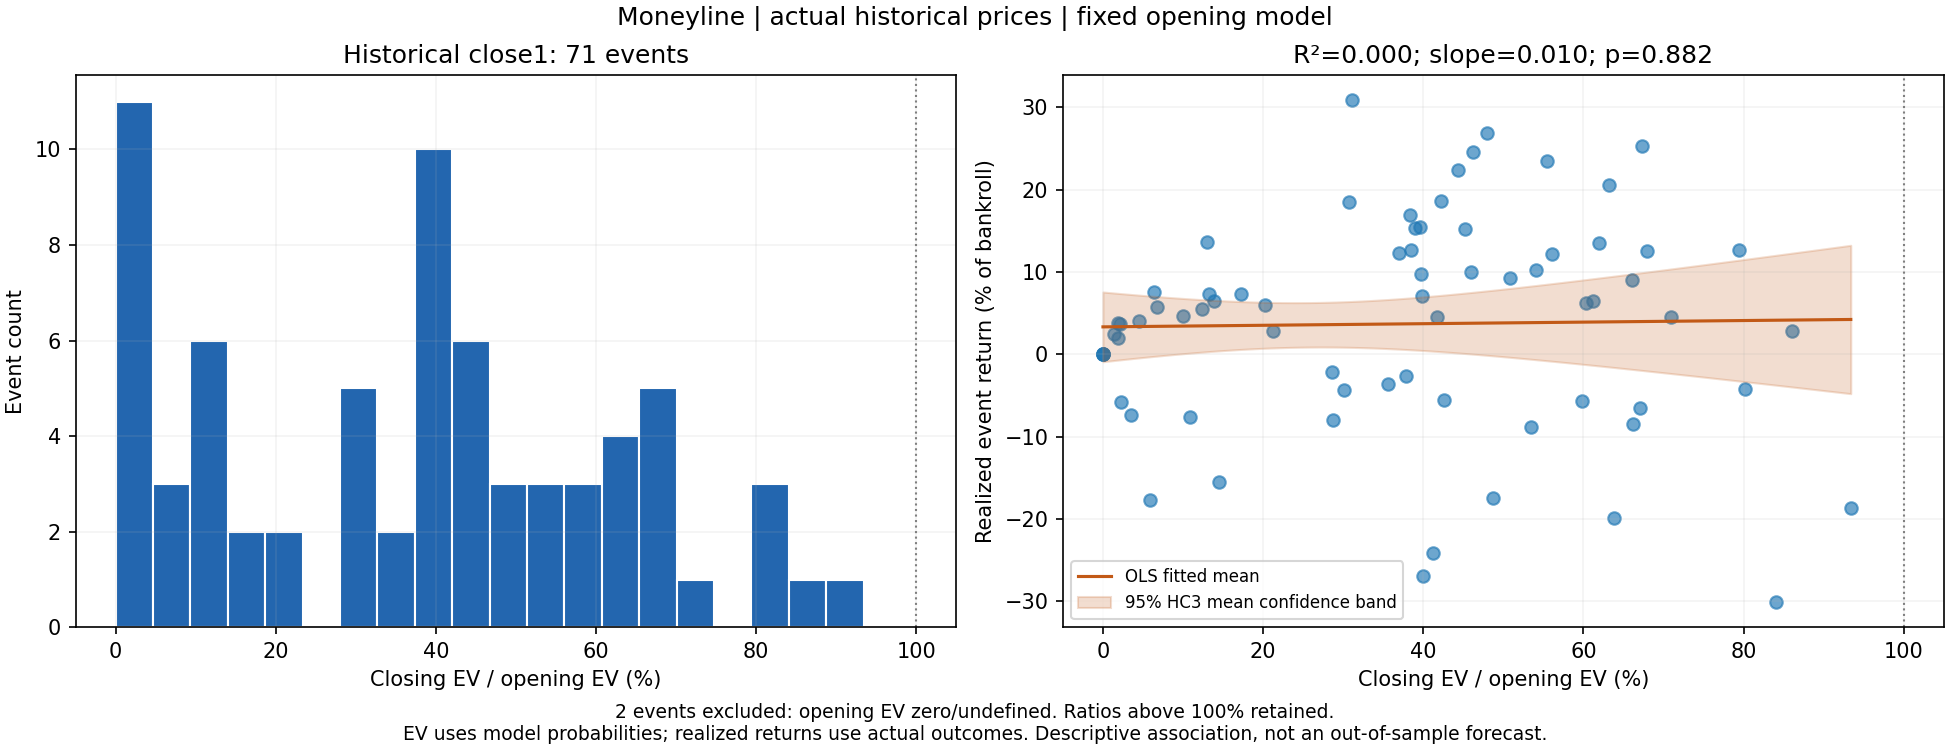

In [5]:
from ufc_betting.Models.RiskManagement.historical_ev_plots import plot_historical_ev

historical_moneylines = plot_historical_ev(
    opening_params, closing_params, strategy="moneyline",
    closing_odds="close1", bins=20,
    output_dir=OUTPUT / "historical" / "moneyline",
)


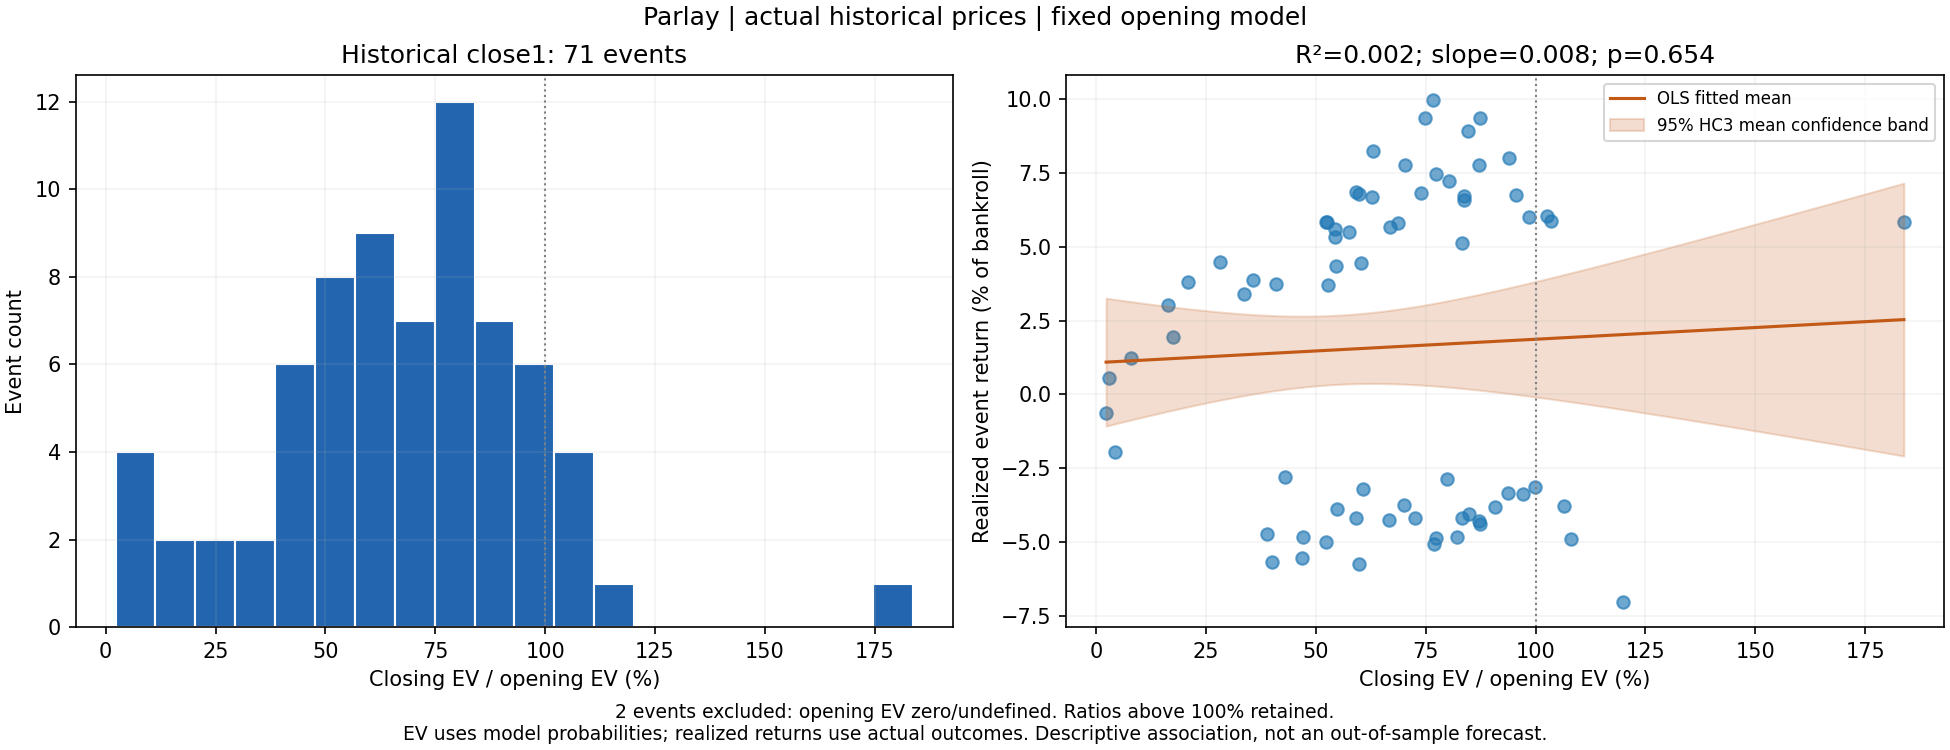

In [6]:
historical_parlays = plot_historical_ev(
    opening_params, closing_params, strategy="parlay",
    closing_odds="close1", bins=20,
    output_dir=OUTPUT / "historical" / "parlay",
)


## Combined moneyline + parlay: historical EV and returns

X = 100 Ãƒâ€” (closing moneyline EV + closing parlay EV) / (opening moneyline EV + opening parlay EV). Y = total realized event return (% of bankroll). Both components share the backtest uncertainty adjustment and exposure cap. Actual historical prices are unchanged.

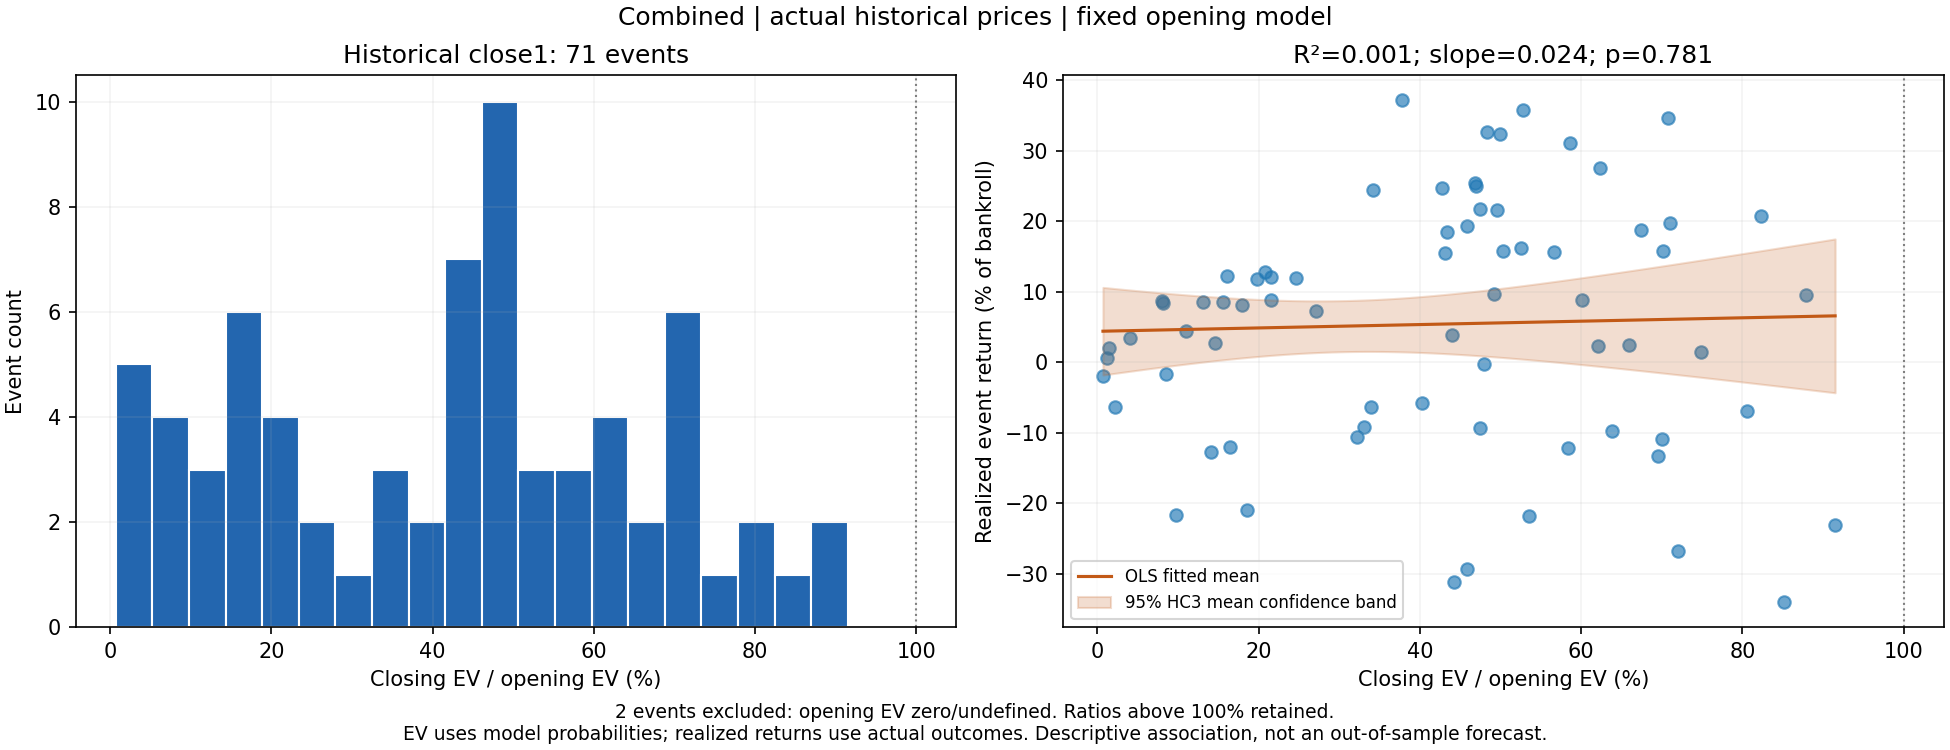

In [7]:
historical_combined = plot_historical_ev(
    opening_params, closing_params, strategy="combined",
    closing_odds="close1", bins=20,
    output_dir=OUTPUT / "historical" / "combined",
)


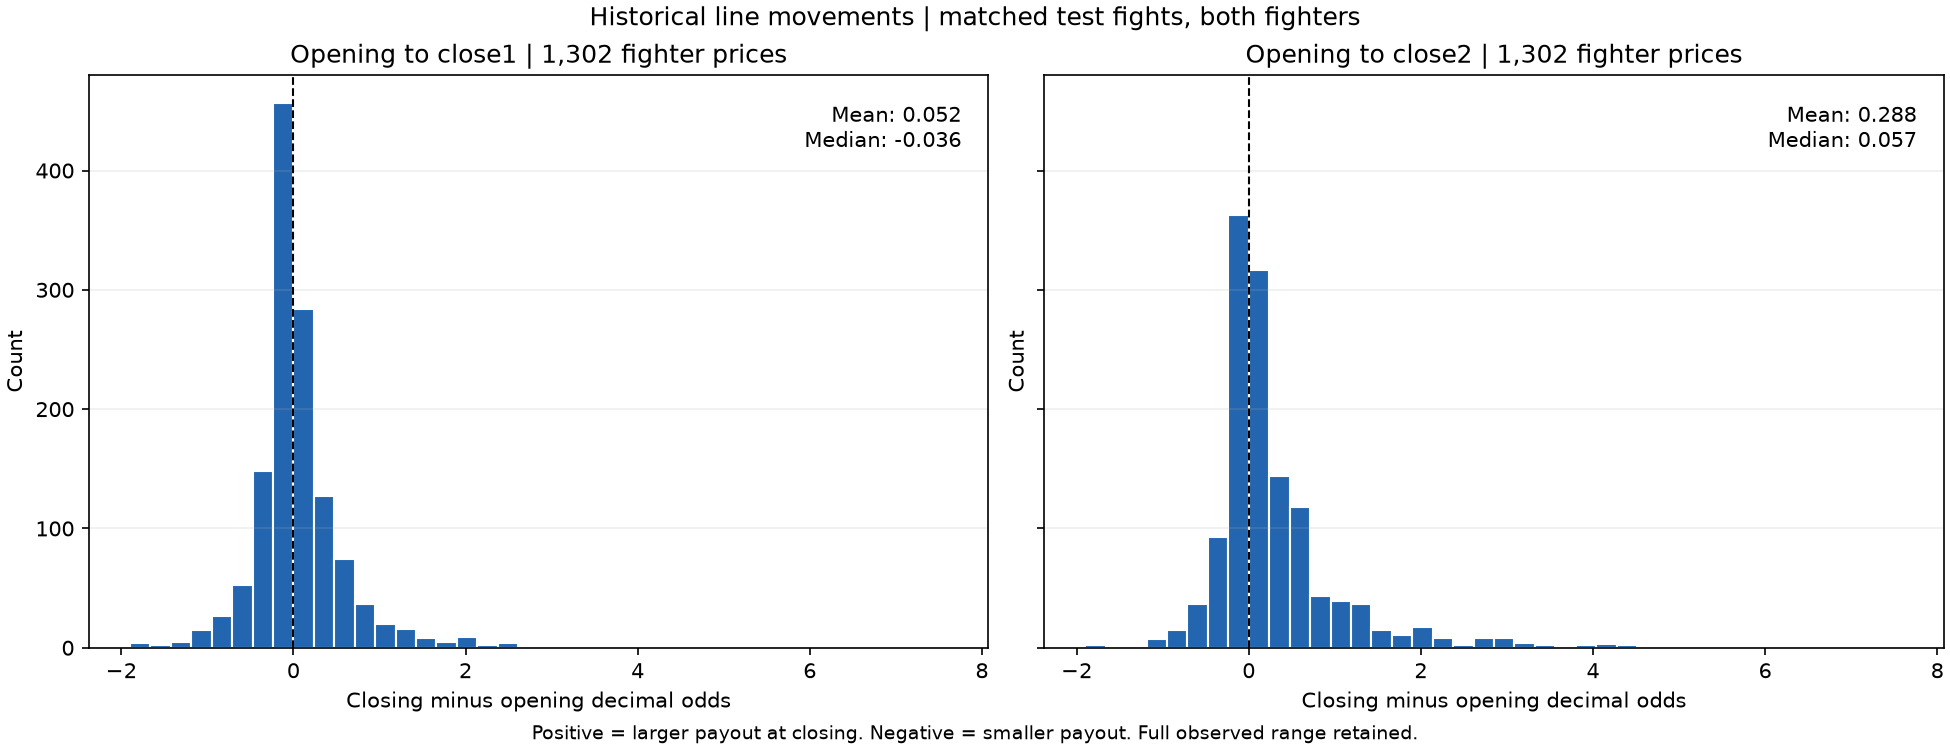

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from historical_ev_plots import plot_line_movement_histograms



line_movements = plot_line_movement_histograms(
    ROOT / "Data" / "model_results",
    bins=40,
    output_dir=OUTPUT / "line_movements",
)


## Line movement versus Kelly fraction change

Separate decreases and increases in decimal odds relative to opening, with close1 and close2 overlaid. X = closing minus opening price; Y = closing minus opening allocated bankroll fraction in percentage points. Uses each snapshot's prices, probabilities and betting parameters. Same fighter at both endpoints; a fighter not selected has zero stake. Only fighters staked at either endpoint are plotted. These endpoints cannot identify a reversal back toward opening.

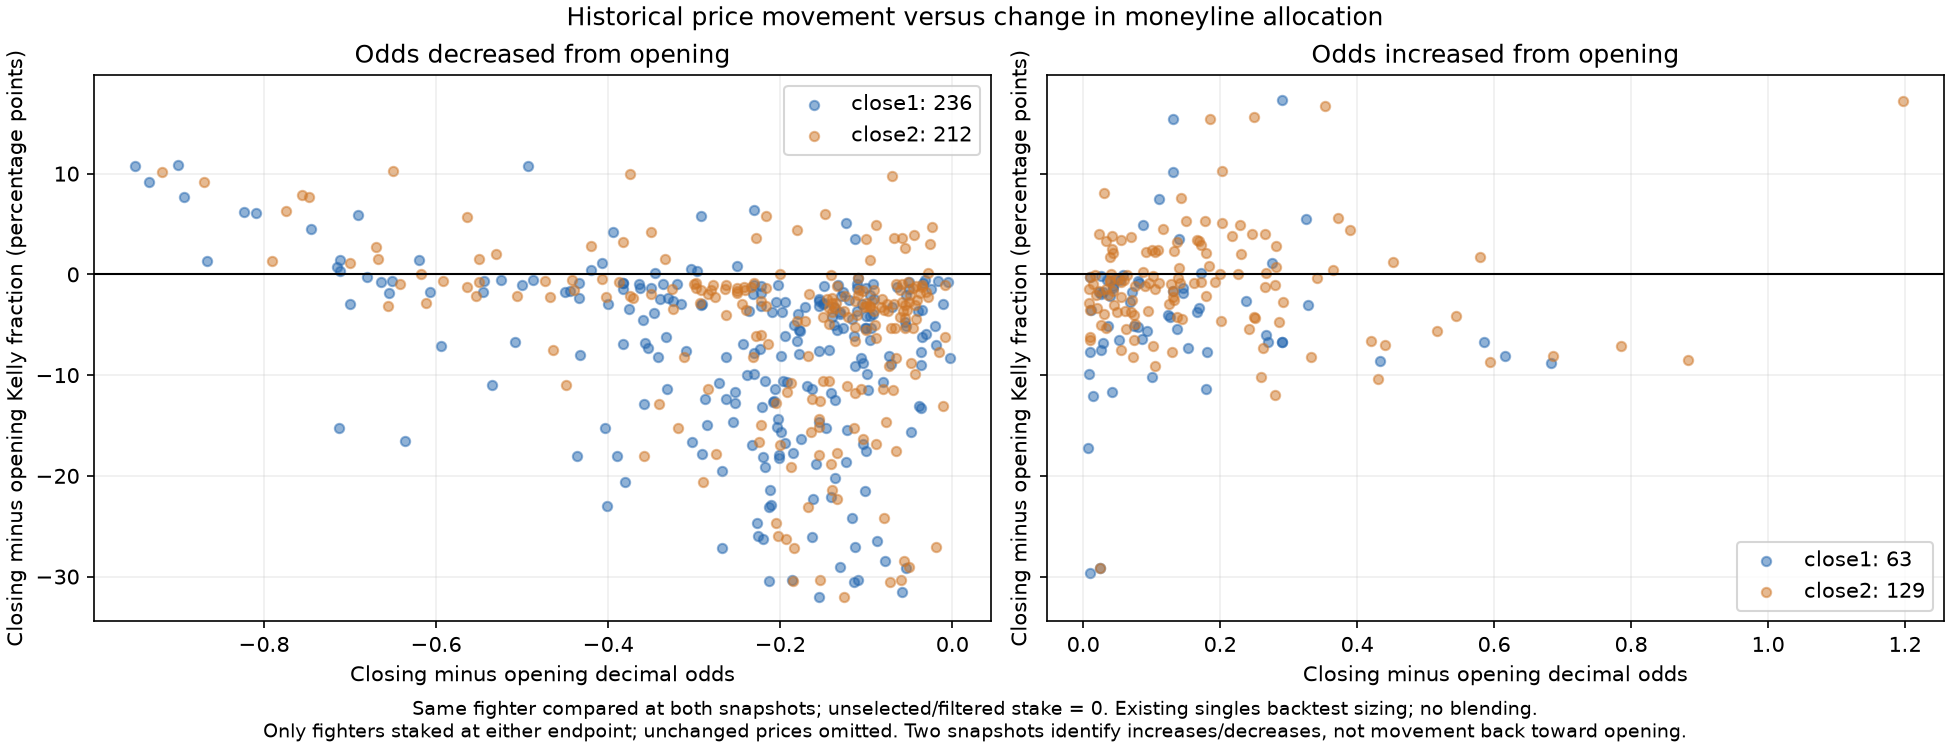

In [17]:
from ufc_betting.Models.RiskManagement.line_movement_kelly import plot_line_movement_kelly

kelly_line_movements = plot_line_movement_kelly(
    opening_params, closing_params,
    output_dir=OUTPUT / "line_movements",
)


## Opening event EV regressed on closing event EV
Combined moneyline + parlay expected returns, as percentages of bankroll. Actual historical prices; no decay or interpolation. The existing closing parameters are used for both close1 and close2; pass a different `close2_params` if desired. Includes zero-EV events.

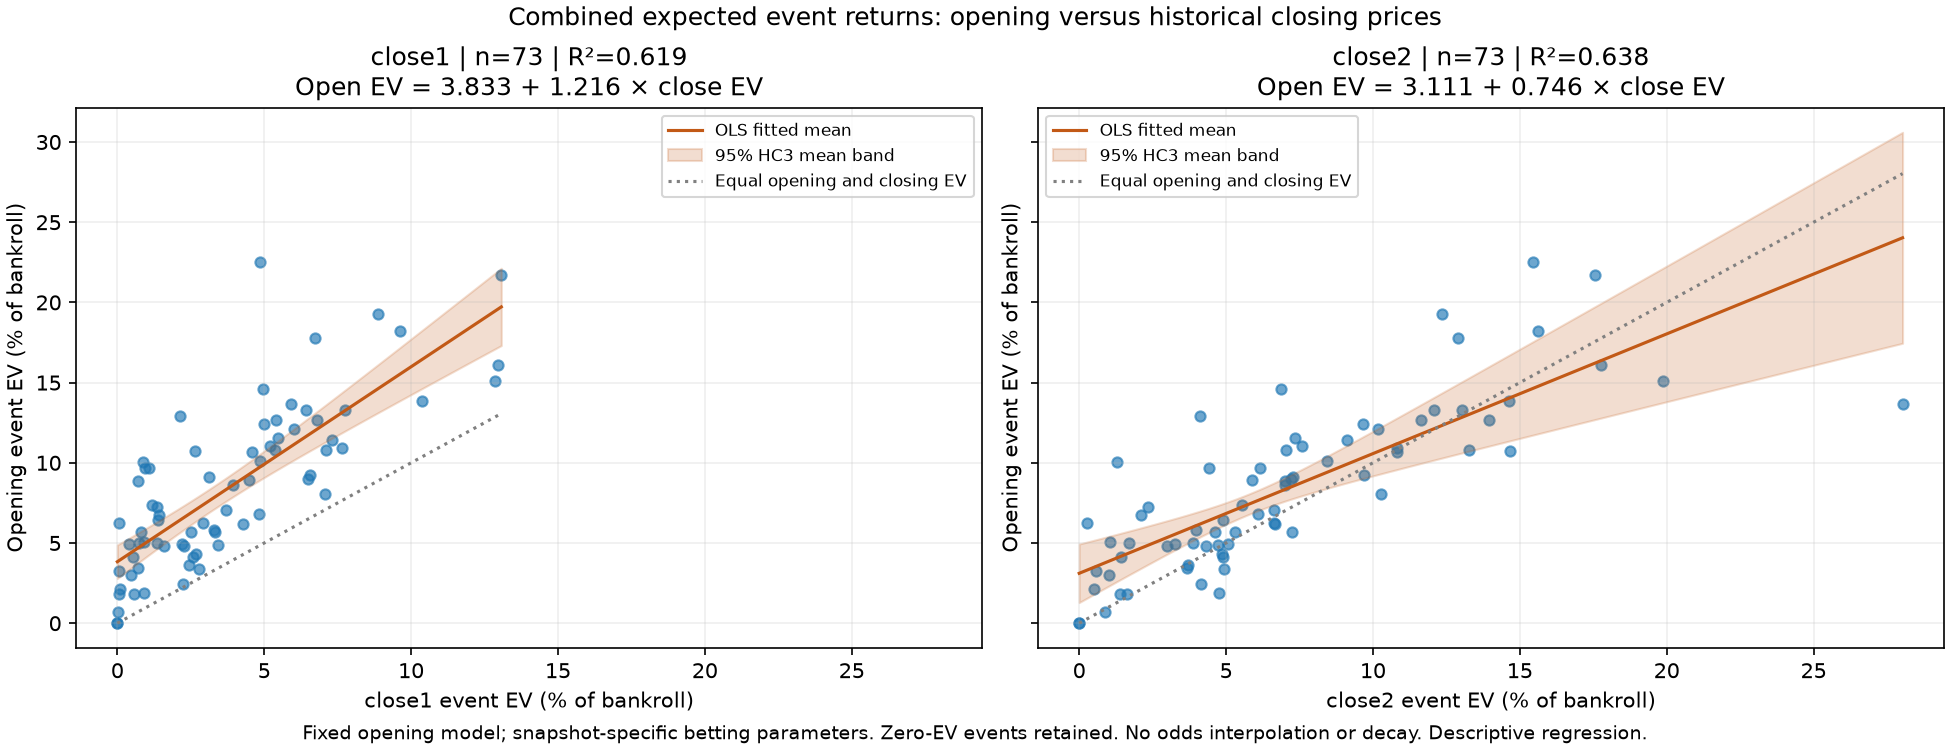

In [20]:
from ufc_betting.Models.RiskManagement.historical_ev_plots import plot_open_vs_close_ev

open_close_ev_regressions = plot_open_vs_close_ev(
    opening_params=opening_params,
    close1_params=closing_params,
    close2_params=closing_params,
    strategy="combined",  # also accepts "moneyline" or "parlay"
    output_dir=OUTPUT / "open_vs_close_ev",
)


## Intermediate historical odds: decay and gain over time

Four separate plots use `Data/intermediate_odds_stats`: close1 decreases, close1 gains, close2 decreases, and close2 gains. **Movement = 100 * (recorded closing decimal odds / recorded opening decimal odds - 1)**. A move from 2.00 to 1.80 is -10%; 2.00 to 2.20 is +10%. These are price changes, not EV, returns, or fitted allocation-decay rates.

Each sample is one fighter/matchup on one UTC calendar day, using the latest committed observation that day. Both fighters are included. The x-axis approaches the event from left to right. Set `max_days=None` for all available pre-event days. Opening is the opening price recorded in the same CSV. Missing days are not filled; invalid prices are excluded. Event-day and later commits are excluded because event start times are unknown. Commit time is a proxy for observation time, not verified scrape time.

Solid lines are daily means; dashed lines are medians; shading is the middle 50% of observations, **not a confidence interval**. Bars show daily sample counts. The table also counts unchanged prices, omitted from the curves. Fighters can switch direction groups across days, and the mix of events varies with archive coverage: these are descriptive daily averages, not a fixed cohort trajectory. Repeated observations and opposing fighters are not independent. This archive is not restricted to the model test set.


odds_type,direction,fighter_day_samples,events
close1,decay,4576,30
close1,gain,2918,30
close1,unchanged,426,30
close2,decay,3450,29
close2,gain,4126,30
close2,unchanged,344,28


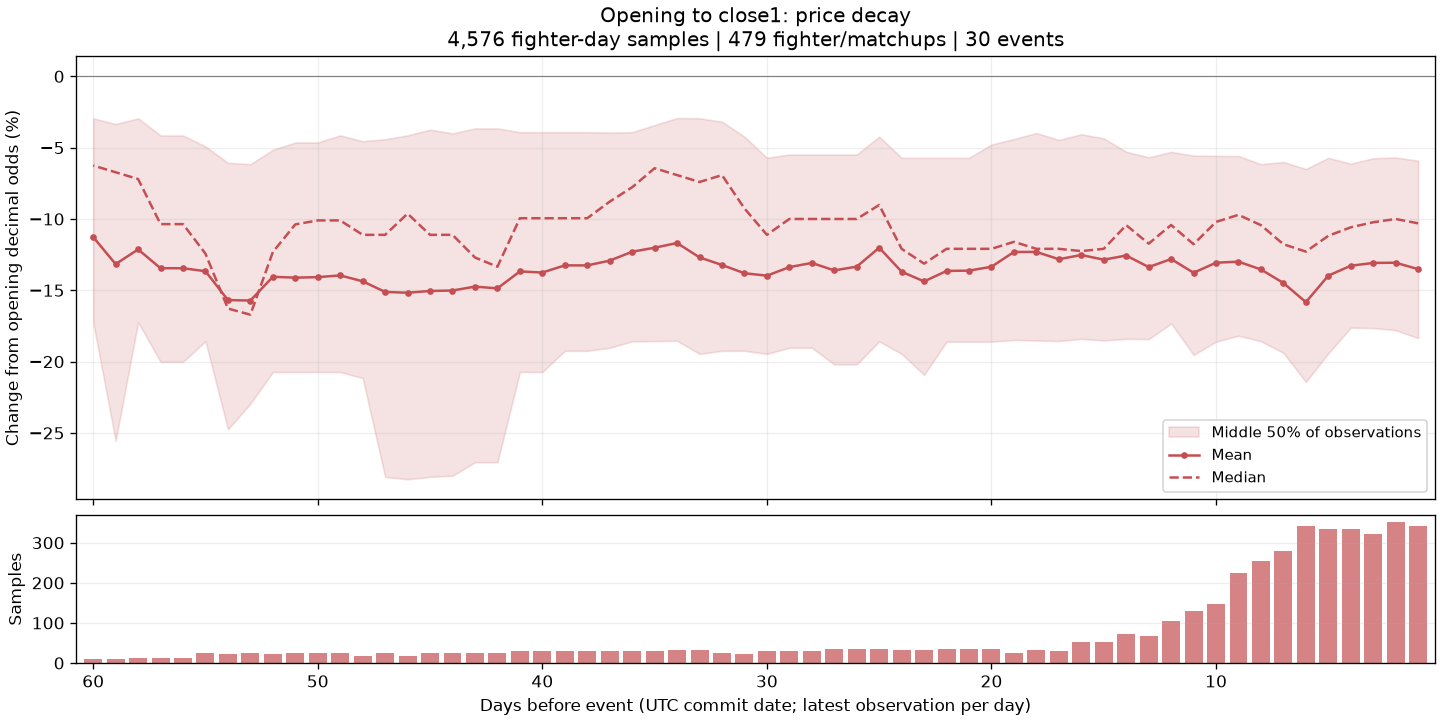

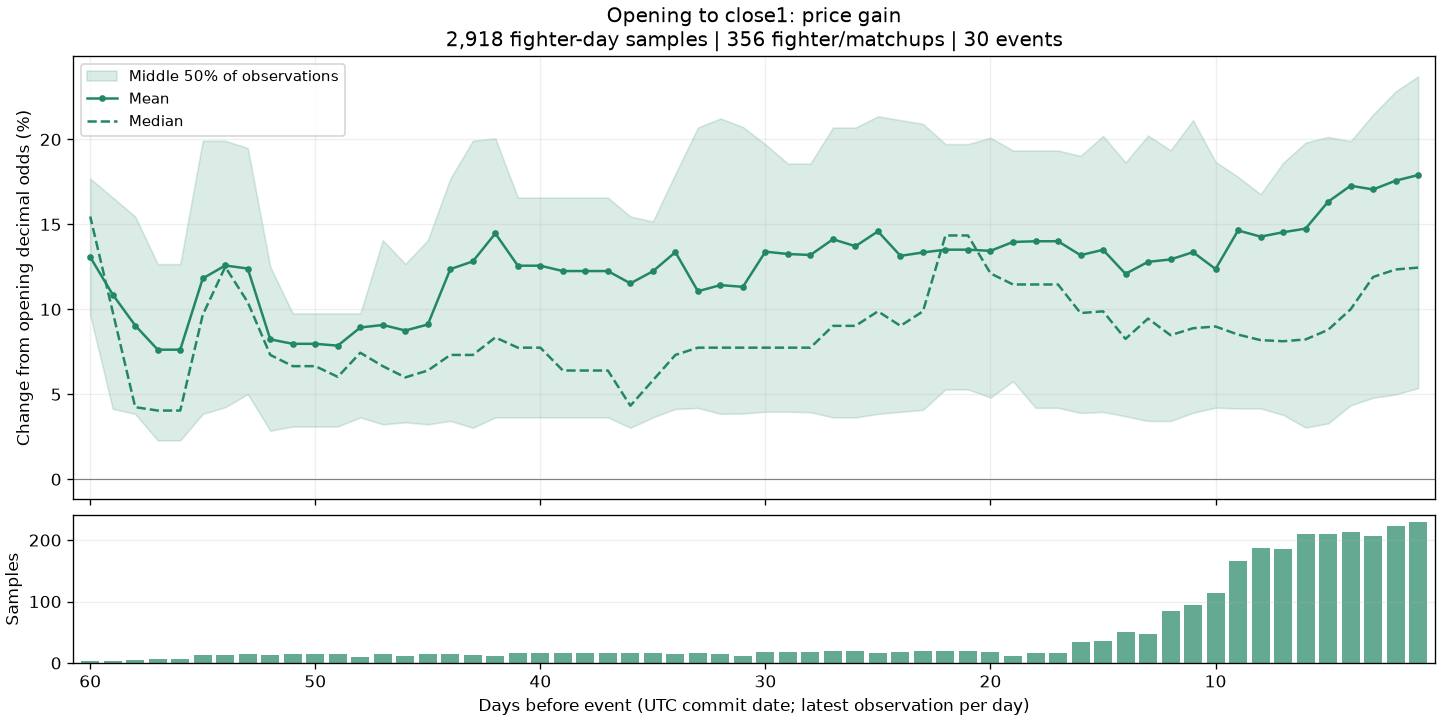

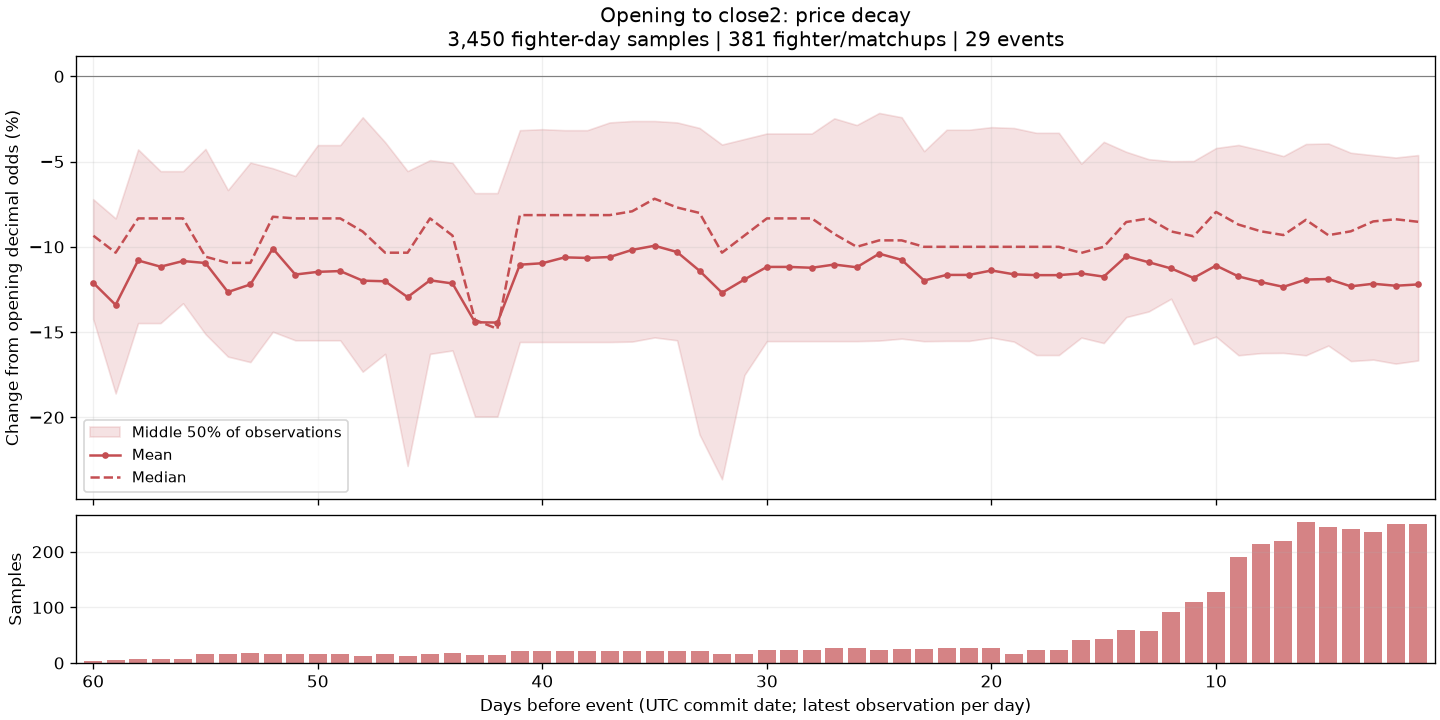

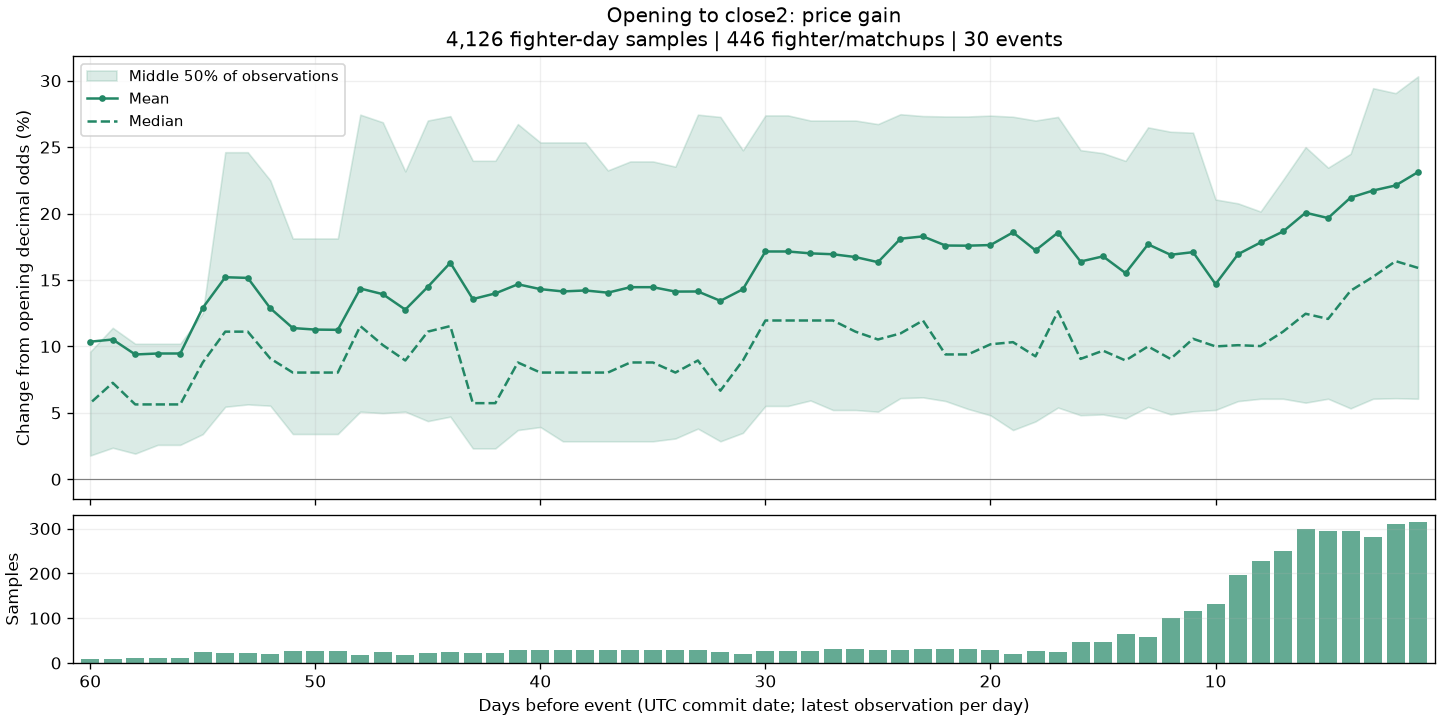

In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.Models.RiskManagement.intermediate_odds_plots import plot_intermediate_odds_movements

intermediate_movements = plot_intermediate_odds_movements(
    ROOT / "Data" / "intermediate_odds_stats",
    max_days=60,  # None includes every available pre-event day
    output_dir=ROOT / "Data" / "plot_pngs" / "intermediate_odds_movements",
)
display(intermediate_movements["counts"])
plt.show()


## First committed event snapshots: opening versus closing odds

Select the earliest UTC commit for **each event** from the intermediate archive, then regress the close1 and close2 prices recorded in that same CSV on its opening prices. Both fighter sides are included; x and y use decimal odds. These are the closing columns as recorded in the first snapshot, not necessarily final pre-fight closing prices. No time-window or pre-event filter is applied. The earliest archived commit may itself be later than the event or the original scrape.

Each plot shows an OLS regression with intercept, sample count, R-squared, and the unchanged-price line (y = x). Missing/nonfinite prices and decimal odds <= 1 are excluded separately for each regression; a later CSV is never substituted. These are descriptive regressions, with no independence-based confidence intervals. `selected_snapshots` preserves the chosen filenames and commit timestamps.


odds_type,samples,events,intercept,slope,r_squared,excluded_price_rows
close1,148,14,0.392815,0.779165,0.797951,286
close2,148,14,0.061931,1.026573,0.830880,286


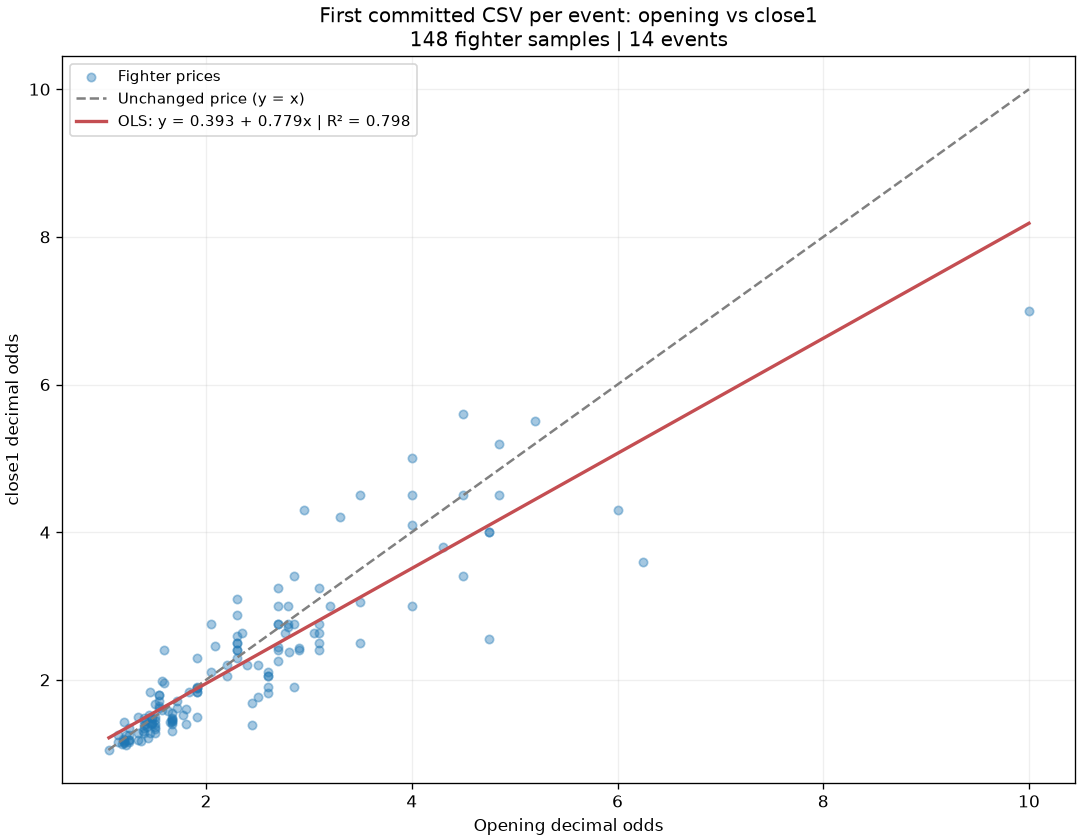

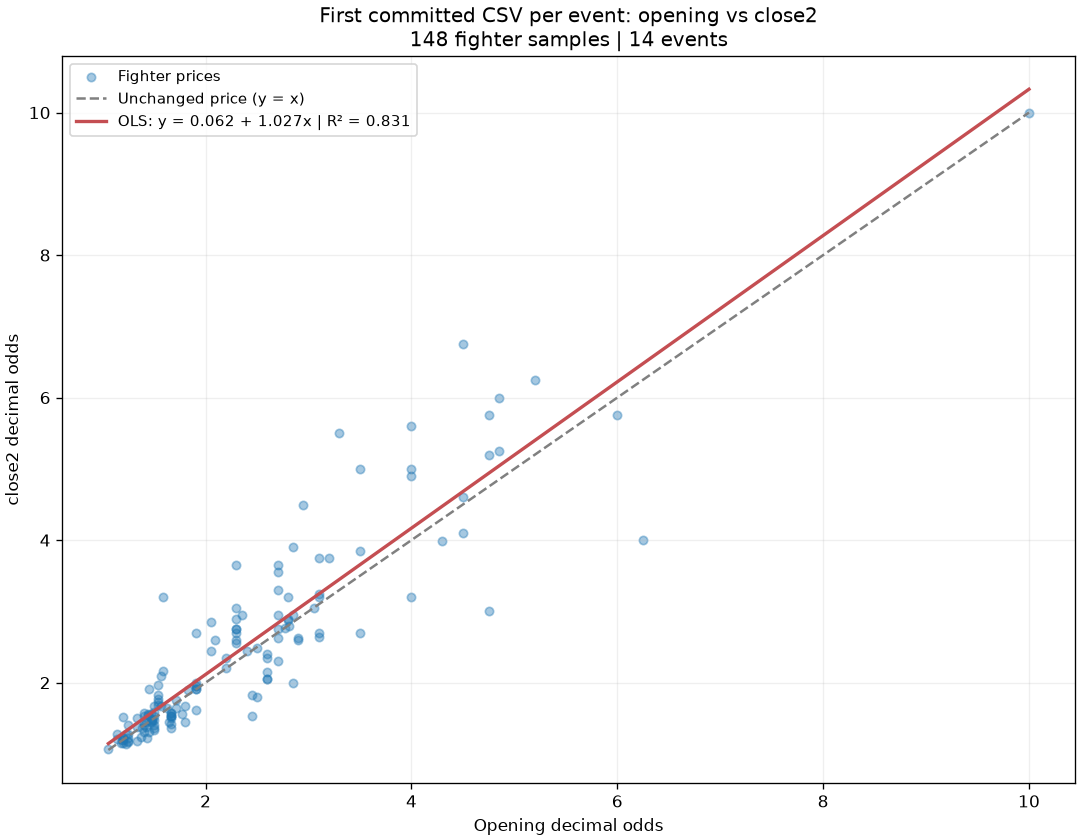

In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.Models.RiskManagement.intermediate_odds_plots import plot_first_snapshot_regressions

first_snapshot_regressions = plot_first_snapshot_regressions(
    ROOT / "Data" / "intermediate_odds_stats",
    output_dir=ROOT / "Data" / "plot_pngs" / "intermediate_odds_movements",
)
display(first_snapshot_regressions["summary"])
plt.show()


## First committed snapshots: distribution of opening-to-closing changes

Uses the same earliest CSV per event as the regressions above. X = closing decimal odds minus opening decimal odds; Y = fighter count. Negative values mean a smaller payout, positive values a larger payout. Both fighter sides and unchanged prices are included. Close1 and close2 use identical bins. These are the closing columns recorded in the first snapshot, not necessarily final closing prices. Run the preceding regression cell first.


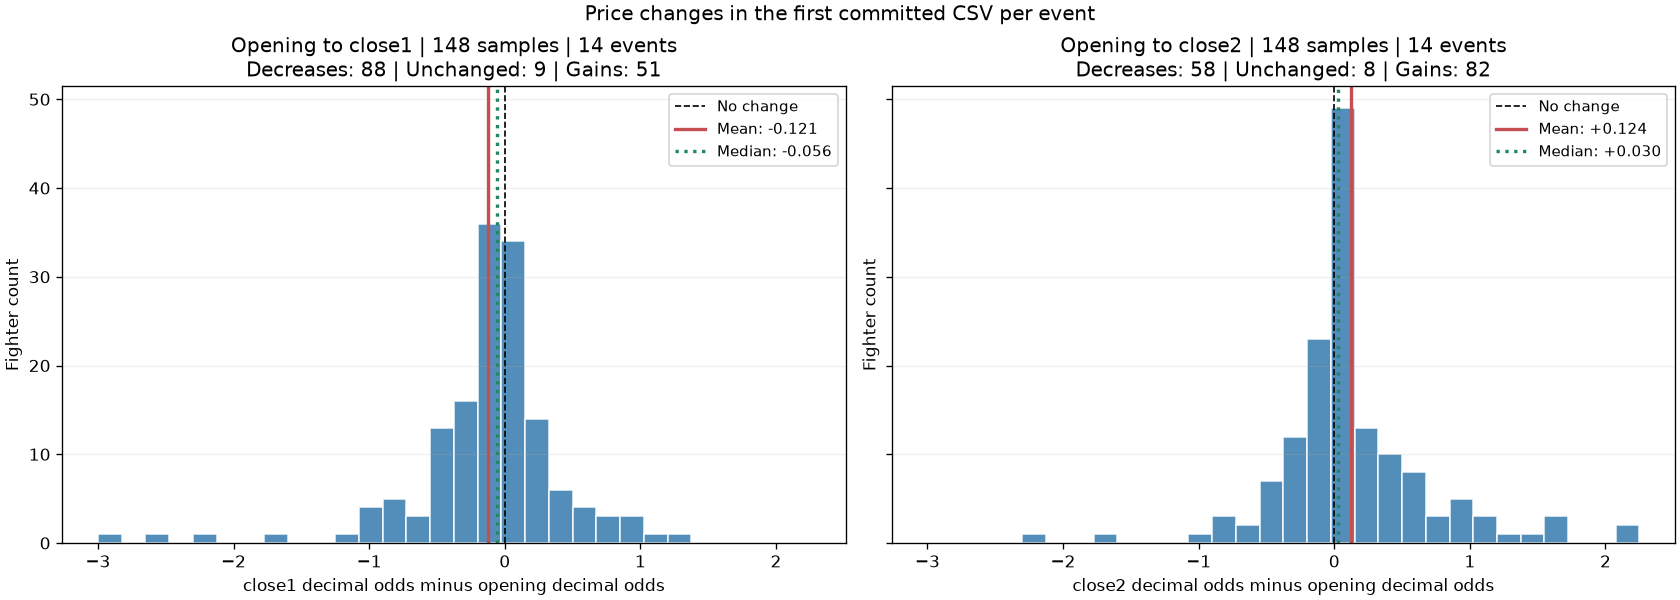

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Uses the first committed event snapshots selected in the preceding cell.
first_snapshot_changes = {}
for stage in ("close1", "close2"):
    prices = first_snapshot_regressions["observations"]
    valid = prices.loc[
        np.isfinite(prices["open"]) & np.isfinite(prices[stage])
        & prices["open"].gt(1) & prices[stage].gt(1)
    ].copy()
    valid["decimal_change"] = valid[stage] - valid["open"]
    first_snapshot_changes[stage] = valid

# Identical bin edges and axis limits make the two distributions comparable.
all_changes = np.concatenate([
    data["decimal_change"].to_numpy() for data in first_snapshot_changes.values()
])
change_bins = np.histogram_bin_edges(all_changes, bins=30)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True, layout="constrained")
for ax, (stage, data) in zip(axes, first_snapshot_changes.items()):
    changes = data["decimal_change"]
    ax.hist(changes, bins=change_bins, color="#3579ad", edgecolor="white", alpha=.85)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="No change")
    ax.axvline(changes.mean(), color="#c44e52", linewidth=2,
               label=f"Mean: {changes.mean():+.3f}")
    ax.axvline(changes.median(), color="#228765", linestyle=":", linewidth=2,
               label=f"Median: {changes.median():+.3f}")
    unchanged = np.isclose(changes, 0, atol=1e-9)
    down = ((changes < 0) & ~unchanged).sum()
    up = ((changes > 0) & ~unchanged).sum()
    ax.set_title(f"Opening to {stage} | {len(data)} samples | {data.event_date.nunique()} events\n"
                 f"Decreases: {down} | Unchanged: {unchanged.sum()} | Gains: {up}")
    ax.set_xlabel(f"{stage} decimal odds minus opening decimal odds")
    ax.set_ylabel("Fighter count")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=.2)
fig.suptitle("Price changes in the first committed CSV per event")
fig.savefig(ROOT / "Data" / "plot_pngs" / "intermediate_odds_movements" / "first_snapshot_change_histograms.png", dpi=150)
plt.show()


## Six days before the event: moneyline EV as a percentage of opening

Select the latest committed CSV on the UTC calendar date exactly six days before each event. Copies are unchanged in `Data/odds_stats_6_days`; its manifest records selected commits. `missing_six_day_events.csv` lists events with no exact-day snapshot. No nearest-date substitution. Commit date is a proxy for scrape date.

Each histogram observation is an event: **100 * six-day expected moneyline bankroll return / opening expected moneyline bankroll return**. Both use the same eligible fights and saved opening model, recomputing market features, probabilities, fair odds, and stakes at each price set. Uses the `opening_params` and `closing_params` defined above, with no decay or parlays. Prices are the opening/close1/close2 columns recorded six days before the event, not final closing prices. Missing features/prices exclude the same fights from numerator and denominator; the table reports those exclusions. Events without positive opening EV are omitted; ratios above 100% are retained.

This is model-implied EV from the current saved model, not realized returns or a walk-forward test. Outcomes are not used in the EV calculation. Archive events are not restricted to the test set.

Histogram-only exclusion: **2026-08-08** is retained in the full event table but omitted from both plots. Set `exclude_event_dates=[]` to restore it.


Selected 26 events; 11 have no exact six-day snapshot.


,event_date,odds_type,fights,excluded_fights,filename,opening_ev_pct,six_day_ev_pct,pct_ev_of_open
0,2026-03-21,close1,8,6,upcoming_odds_stats_2026-03-21_2026-03-15T21-3...,9.027731,6.059008,67.115507
1,2026-03-21,close2,8,6,upcoming_odds_stats_2026-03-21_2026-03-15T21-3...,9.027731,9.049178,100.237571
2,2026-03-28,close1,10,4,upcoming_odds_stats_2026-03-28_2026-03-22T21-2...,11.617693,6.870551,59.138686
3,2026-03-28,close2,10,4,upcoming_odds_stats_2026-03-28_2026-03-22T21-2...,11.617693,10.341508,89.015158
4,2026-04-04,close1,7,6,upcoming_odds_stats_2026-04-04_2026-03-29T22-3...,2.639578,1.402181,53.121427
5,2026-04-04,close2,7,6,upcoming_odds_stats_2026-04-04_2026-03-29T22-3...,2.639578,3.049931,115.546162
6,2026-04-11,close1,9,2,upcoming_odds_stats_2026-04-11_2026-04-05T21-3...,7.116600,0.000000,0.000000
7,2026-04-11,close2,9,2,upcoming_odds_stats_2026-04-11_2026-04-05T21-3...,7.116600,6.742879,94.748599
8,2026-04-18,close1,7,6,upcoming_odds_stats_2026-04-18_2026-04-12T21-3...,3.604099,1.801687,49.989933
9,2026-04-18,close2,7,6,upcoming_odds_stats_2026-04-18_2026-04-12T21-3...,3.604099,2.850576,79.092627


,event_date,odds_type,fights,excluded_fights,filename,opening_ev_pct,six_day_ev_pct,pct_ev_of_open
36,2026-08-08,close1,7,4,upcoming_odds_stats_2026-08-08_2026-08-02T21-5...,0.104121,2.190725,2104.018374
37,2026-08-08,close2,7,4,upcoming_odds_stats_2026-08-08_2026-08-02T21-5...,0.104121,3.168237,3042.842189


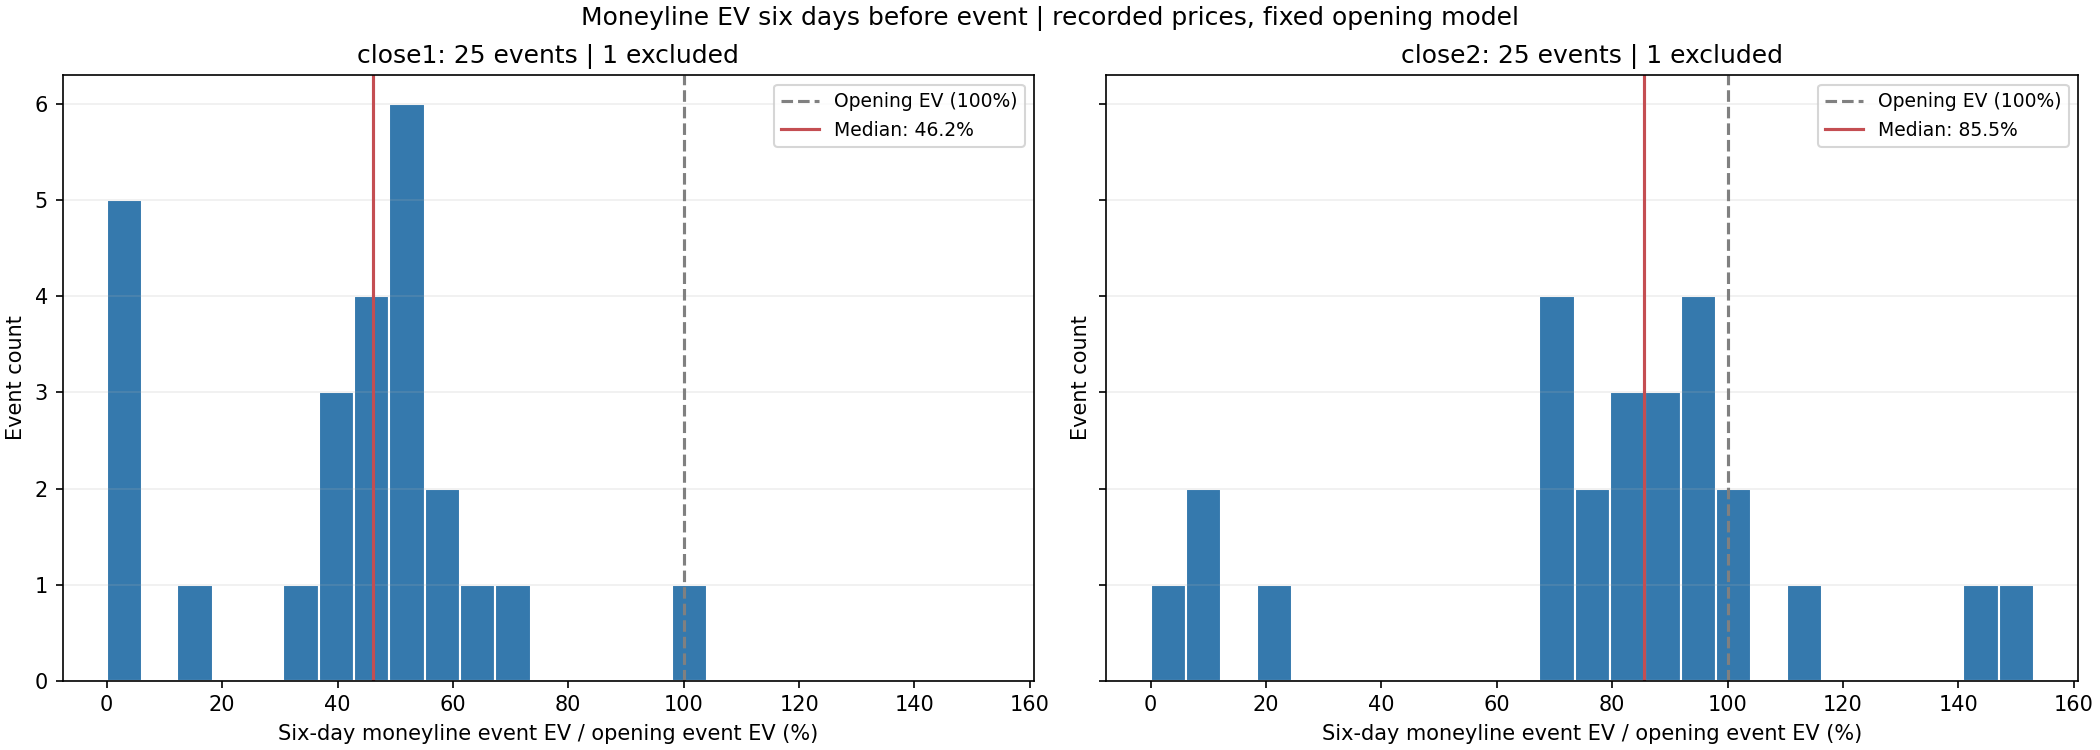

In [8]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
from ufc_betting.Models.RiskManagement.six_day_odds_ev import (
    select_six_day_snapshots, plot_six_day_moneyline_ev,
)

six_day_snapshots, missing_six_day_events = select_six_day_snapshots(
    ROOT / "Data" / "intermediate_odds_stats",
    ROOT / "Data" / "odds_stats_6_days",
)
print(f"Selected {len(six_day_snapshots)} events; {len(missing_six_day_events)} have no exact six-day snapshot.")
six_day_ev = plot_six_day_moneyline_ev(
    ROOT / "Data" / "odds_stats_6_days",
    opening_params=opening_params,
    closing_params=closing_params,
    bins=25,
    exclude_event_dates=["2026-08-08"],  # Histogram only; retained in event table
)
display(six_day_ev["events"])
display(six_day_ev["excluded_events"])
display(Image(filename=str(ROOT / "Data" / "odds_stats_6_days" / "moneyline_pct_open_ev_histogram.png")))
plt.close(six_day_ev["figure"])


## Average moneyline EV over time

One plot shows the close1 daily average, close2 daily average, and their arithmetic midpoint: (close1 average + close2 average) / 2. Each available event has equal weight. X is days before the event; Y is 100 * closing moneyline event EV / opening moneyline event EV. Latest committed snapshot per UTC day; missing days are not filled.

An event is excluded from both averages for the entire displayed window if either series exceeds 300% on any observed day. This is a retrospective filter, not a prospective betting rule. All original values remain in `intermediate_ev["events"]`; excluded rows are in `intermediate_ev["excluded_events"]`. Set `max_event_ev_pct=None` to disable the threshold.

Uses the notebook betting parameters and fixed opening model. Probabilities, fair odds, and stakes are recalculated. Opening EV uses the same eligible fights and features in each snapshot; it is not a frozen first-snapshot benchmark. Changes in card composition and available events affect the averages. This is model-implied EV, not realized returns.


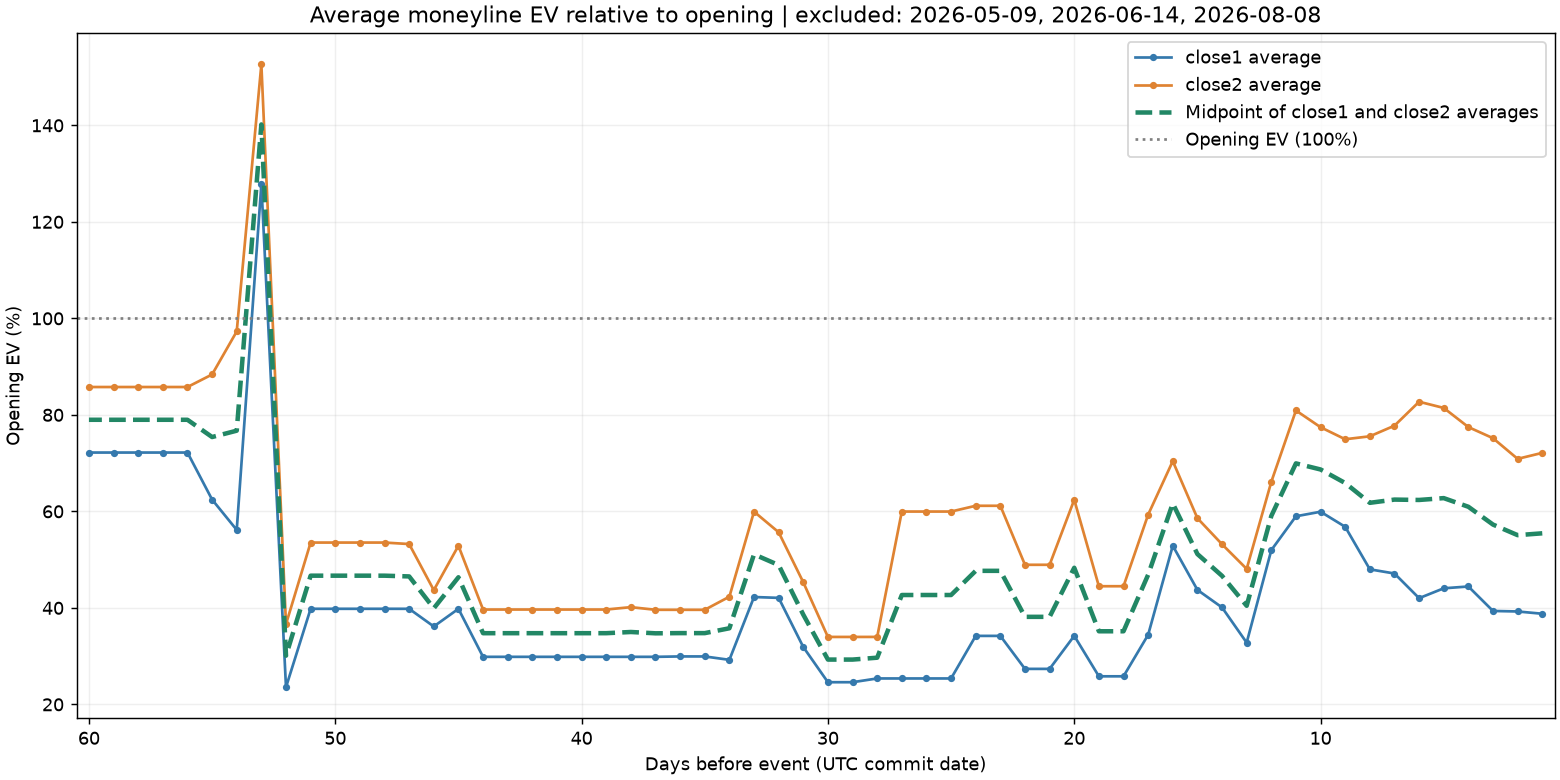

In [ ]:
from pathlib import Path
import sys
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
# Reload shared helpers in case they were imported before this update.
import importlib
from ufc_betting.Models.RiskManagement import six_day_odds_ev, intermediate_ev_plots
importlib.reload(six_day_odds_ev)
importlib.reload(intermediate_ev_plots)

intermediate_ev = intermediate_ev_plots.plot_intermediate_moneyline_ev(
    ROOT / "Data" / "intermediate_odds_stats",
    opening_params=opening_params,
    closing_params=closing_params,
    max_days=60,
    exclude_from_average=[],
    max_event_ev_pct=300,  # Exclude the entire event if either series exceeds this at any observed day
    output_dir=ROOT / "Data" / "plot_pngs" / "intermediate_ev_over_time",
)
display(Image(filename=str(intermediate_ev["average_plot_path"])))
# Tables: intermediate_ev["events"] and intermediate_ev["average"]


## Strategy backtests at 7, 5, and 3 days before events

Replay the joint moneyline + top-EV parlay exponential-decay strategy configured in `kelly_sim_test`. Four lambdas are fixed, and opening/close1/close2 betting controls are loaded from their saved search data. Predictions and fair odds are recomputed using the current saved opening model at the recorded or sampled prices. No search or model refit runs. These are retrospective realized bankroll paths, not a walk-forward validation of the fitted model or controls.

For each event and lead time, use the latest commit on that exact UTC calendar day. Missing exact dates are not substituted. Retain only settled binary-outcome fights with valid features and open/close1/close2 prices at all three lead times, so all paths use the same chronological cohort. Outcomes are joined by event and fighter names from historical results; no later fight features are substituted into snapshots. Cancelled/unmatched fights and draws/no-contests are excluded; the resulting reduced cards are documented in the saved cohort audit. No 300% EV filtering is applied to these backtests.

The first figure shows recorded close1 and close2 prices for each lead time. The second shows uniformly sampled prices: draw U in [0,1] independently per fight and scenario, then use `close1 + U * (close2 - close1)` in decimal odds for both sides of that fight. Both policies receive identical sampled prices. Thin lines are individual realized scenarios; thick lines are pointwise medians, not necessarily a single attainable path. The scenario spread reflects this sampling assumption, not statistical confidence or a forecast of actual available prices.

Uses a $500 initial bankroll, no floor or top-ups, and the decay engine's existing allocation rules without post-blend rescaling. The same close1-fitted lambdas are transferred to close2, as in `kelly_sim_test`. Daily commit timestamps approximate observation times. Saved data include selected snapshots, missing exact dates, cohort audits, random draws, event returns, and path summaries.

All recorded and sampled runs now call `backtest_functions.simulate_kelly` with the decay configuration. Recorded diagnostic figures call `plot_backtest` on the returned Kelly DataFrames. Every comparison/scenario path reads their `bankroll_postevent` values directly; it does not independently compound event returns. Full moneyline and parlay DataFrames are available in `lead_time_results["simulation_results"]` and `simulate_kelly_results.joblib`.

**Split selection:** `days_out` accepts one integer or several. Each split runs separately, using exact event-date and fighter membership from `test_set_data_open_with_open.csv` or `val_set_data_open_with_close1.csv`, including their recorded outcomes. Snapshot features/prices remain the predictor inputs. To use your own split DataFrame, call `run_lead_time_backtests(..., event_data=my_split, days_out=7)`. A date-only DataFrame restricts event dates; including fighter columns also restricts fights. Results are saved separately under `lead_time_backtests/test` and `lead_time_backtests/validation`. No archive coverage yields a missing-date report rather than fabricated bankroll paths.


7 days: 160 fights / 20 events


c:\Users\jcmar\my_files\SportsBetting\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\jcmar\my_files\SportsBetting\src\ufc_betting\BettingStrategy\Backtest\backtest_plots.py:408: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
c:\Users\jcmar\my_files\SportsBetting\src\ufc_betting\BettingStrategy\Backtest\backtest_plots.py:408: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


  5/20 sampled paths complete
  10/20 sampled paths complete
  15/20 sampled paths complete
  20/20 sampled paths complete
5 days: 160 fights / 20 events


c:\Users\jcmar\my_files\SportsBetting\src\ufc_betting\BettingStrategy\Backtest\backtest_plots.py:408: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
c:\Users\jcmar\my_files\SportsBetting\src\ufc_betting\BettingStrategy\Backtest\backtest_plots.py:408: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


  5/20 sampled paths complete
  10/20 sampled paths complete
  15/20 sampled paths complete
  20/20 sampled paths complete
3 days: 160 fights / 20 events


...

  5/20 sampled paths complete
  10/20 sampled paths complete
  15/20 sampled paths complete
  20/20 sampled paths complete
test: complete | 20 events


,event_date,missing_days
0,2026-02-28,"3,5,7"
1,2026-03-07,"3,5,7"
2,2026-03-14,"3,7"
3,2026-03-21,7
4,2026-04-04,7
5,2026-04-11,3
6,2026-05-02,5
7,2026-09-05,"3,5"


,date
0,2026-03-28
1,2026-04-18
2,2026-04-25
3,2026-05-09
4,2026-05-16
5,2026-05-30
6,2026-06-06
7,2026-06-14
8,2026-06-20
9,2026-06-27


count      median         min         max
scenario days_out policy                                           
recorded 3        close1      1  270.139560  270.139560  270.139560
                  close2      1  265.296749  265.296749  265.296749
         5        close1      1  218.441084  218.441084  218.441084
                  close2      1  326.514894  326.514894  326.514894
         7        close1      1  324.040226  324.040226  324.040226
                  close2      1  384.600934  384.600934  384.600934
uniform  3        close1     20  296.040111  229.071804  436.678332
                  close2     20  305.987137  241.958839  422.127591
         5        close1     20  285.404519  237.477258  343.142408
                  close2     20  321.198122  258.990361  449.630298
         7        close1     20  417.993854  316.751687  564.957282
                  close2     20  373.877952  276.429748  499.444240

recorded_7_days_close1


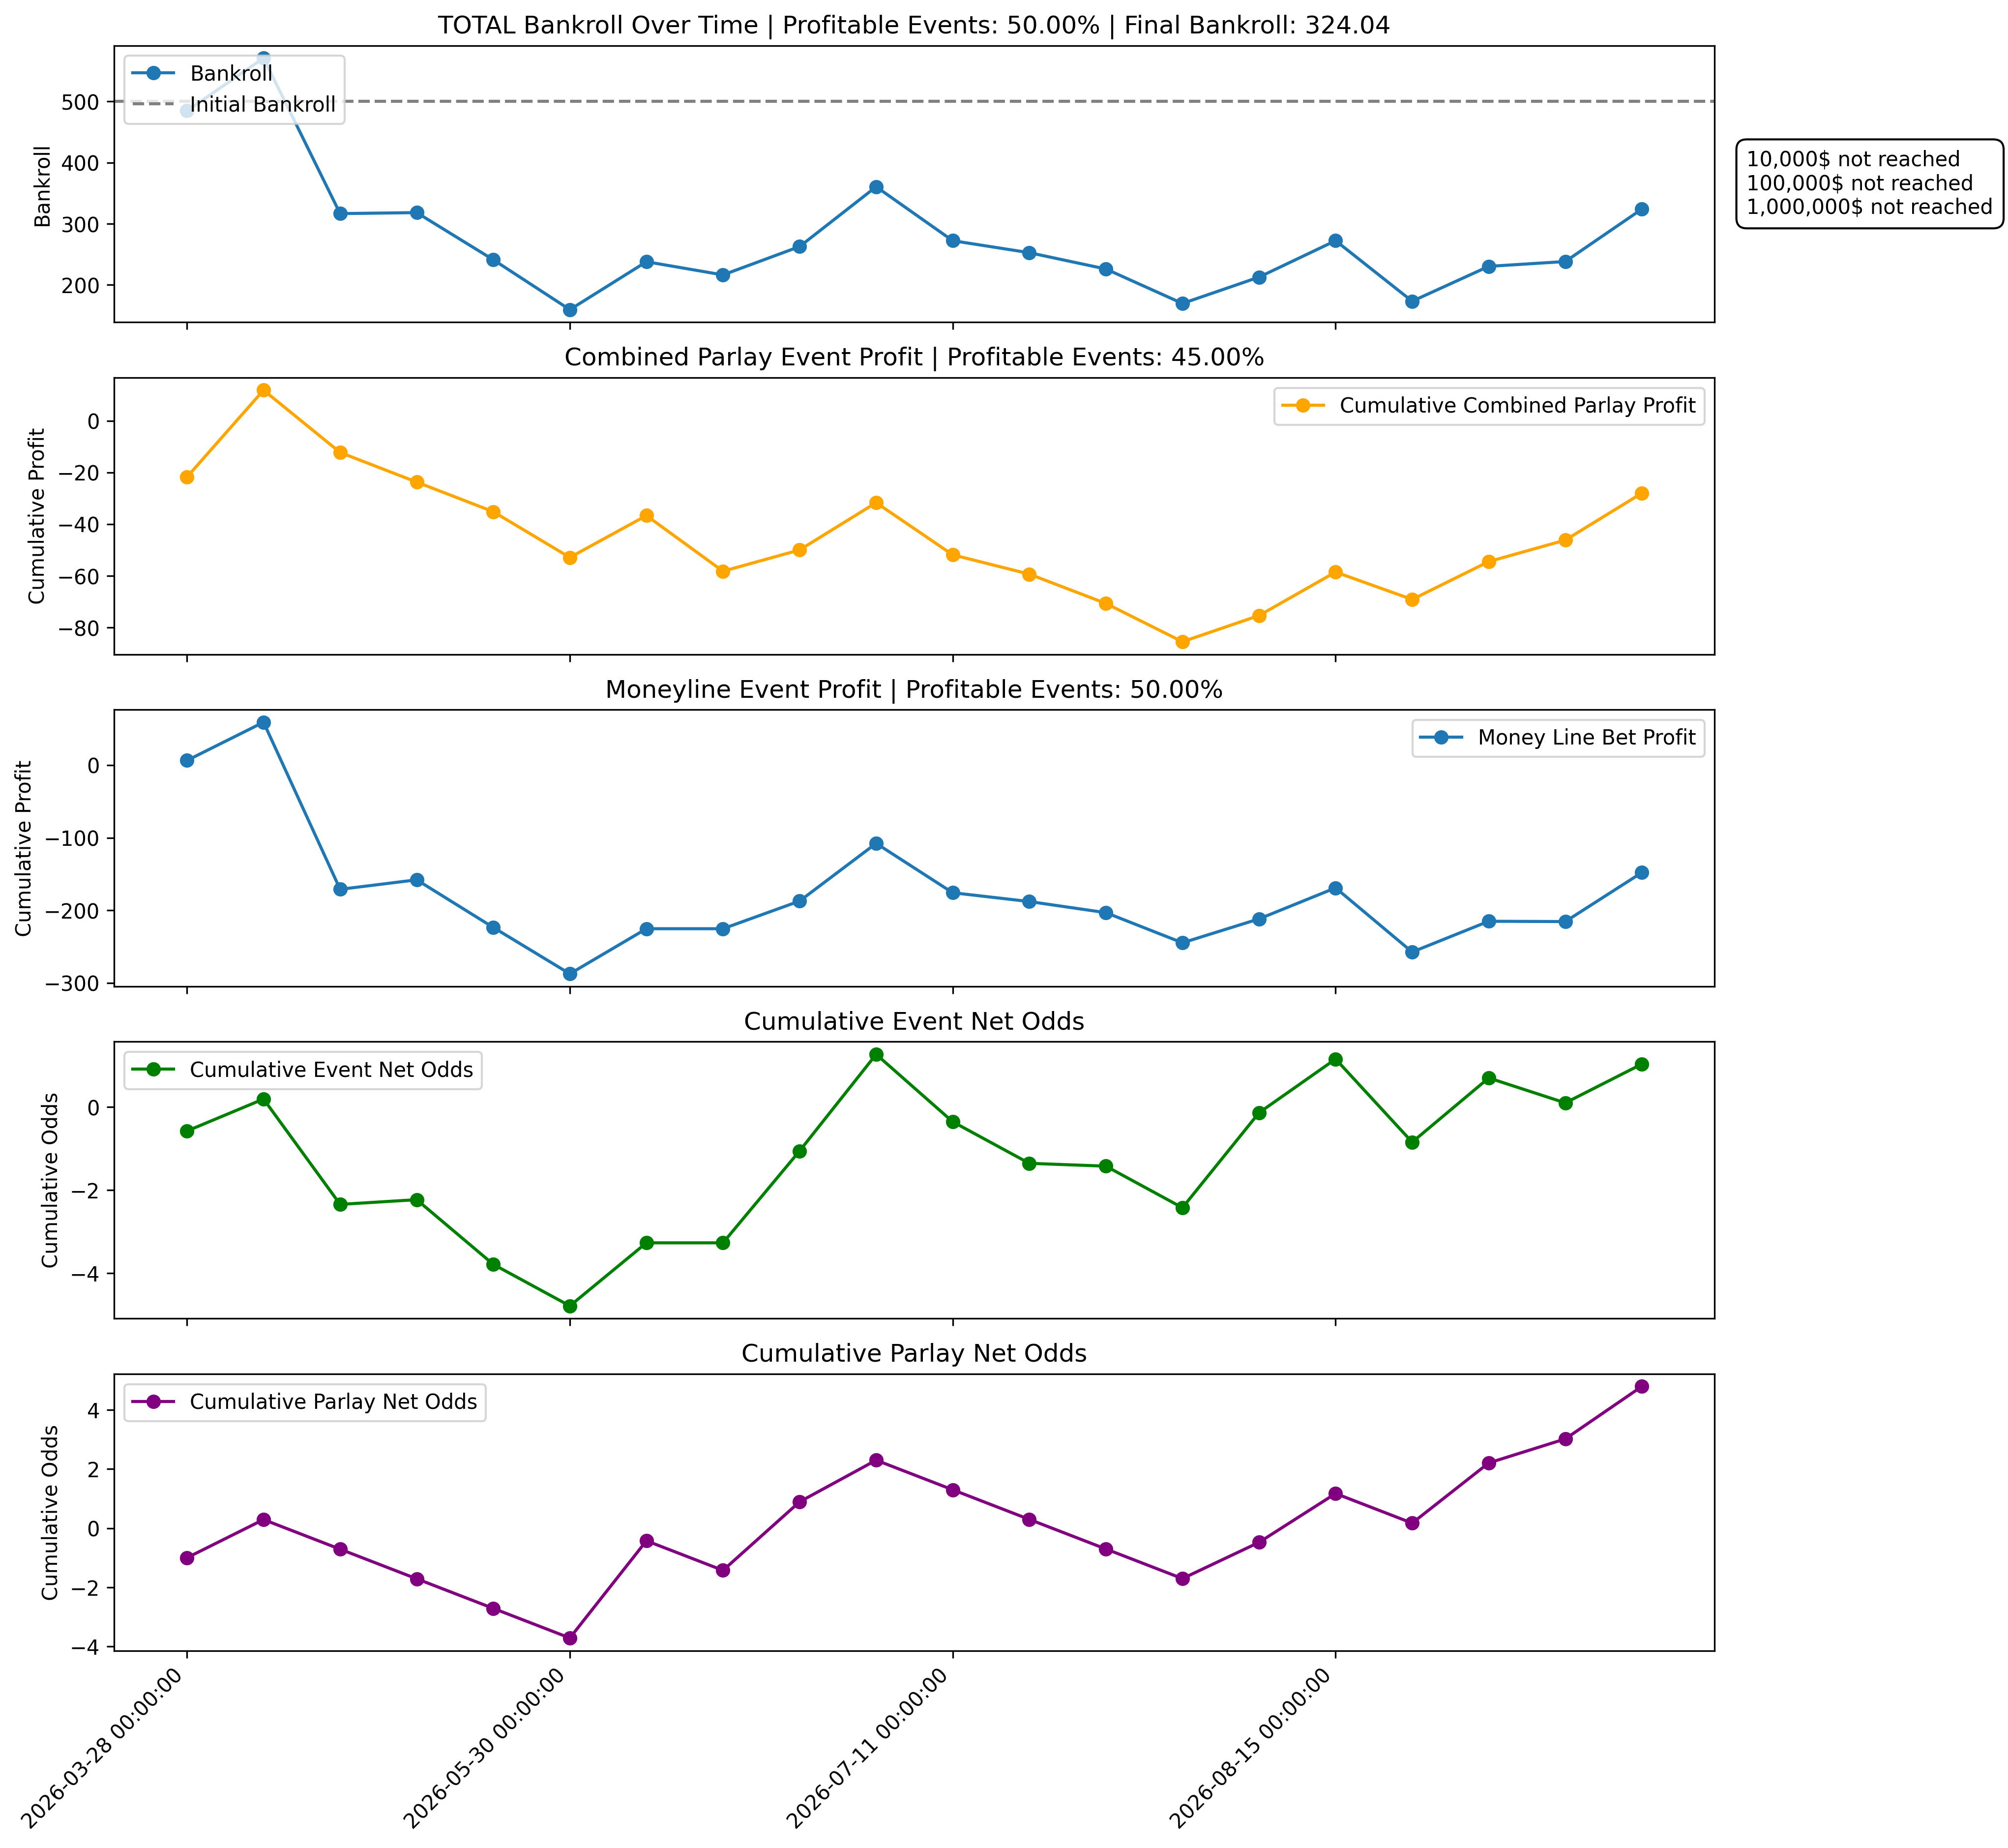

recorded_7_days_close2


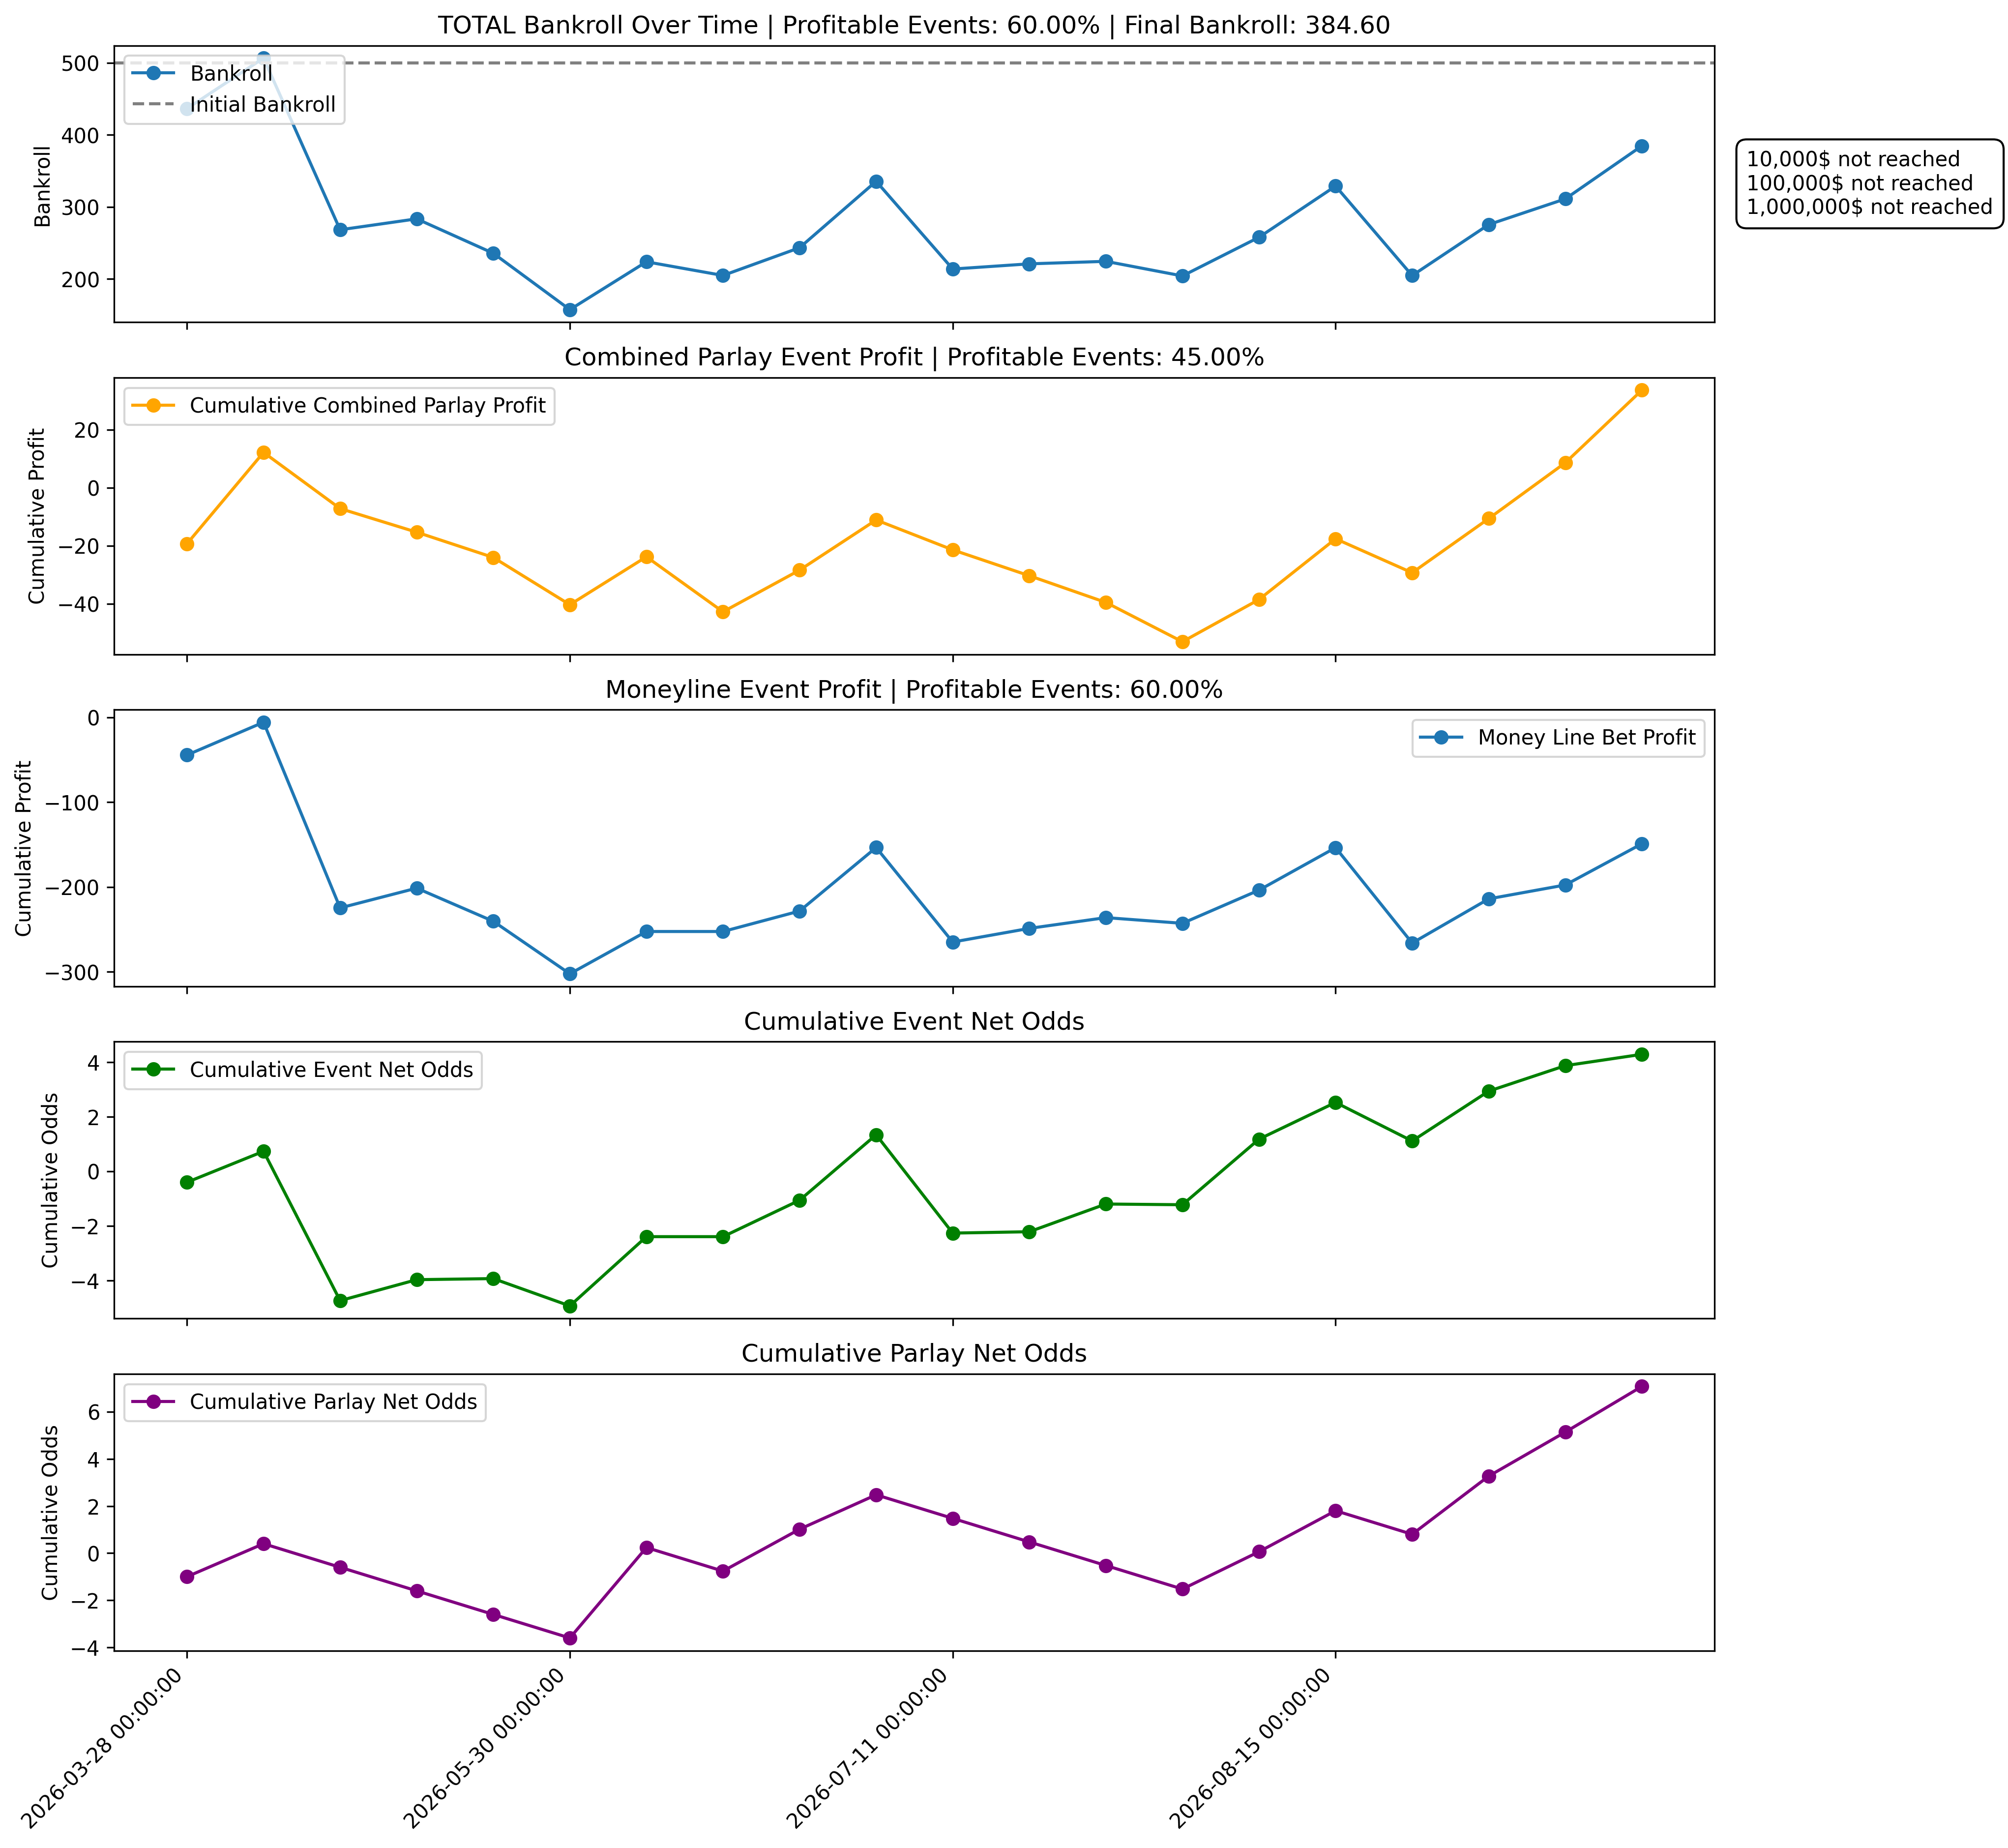

recorded_5_days_close1


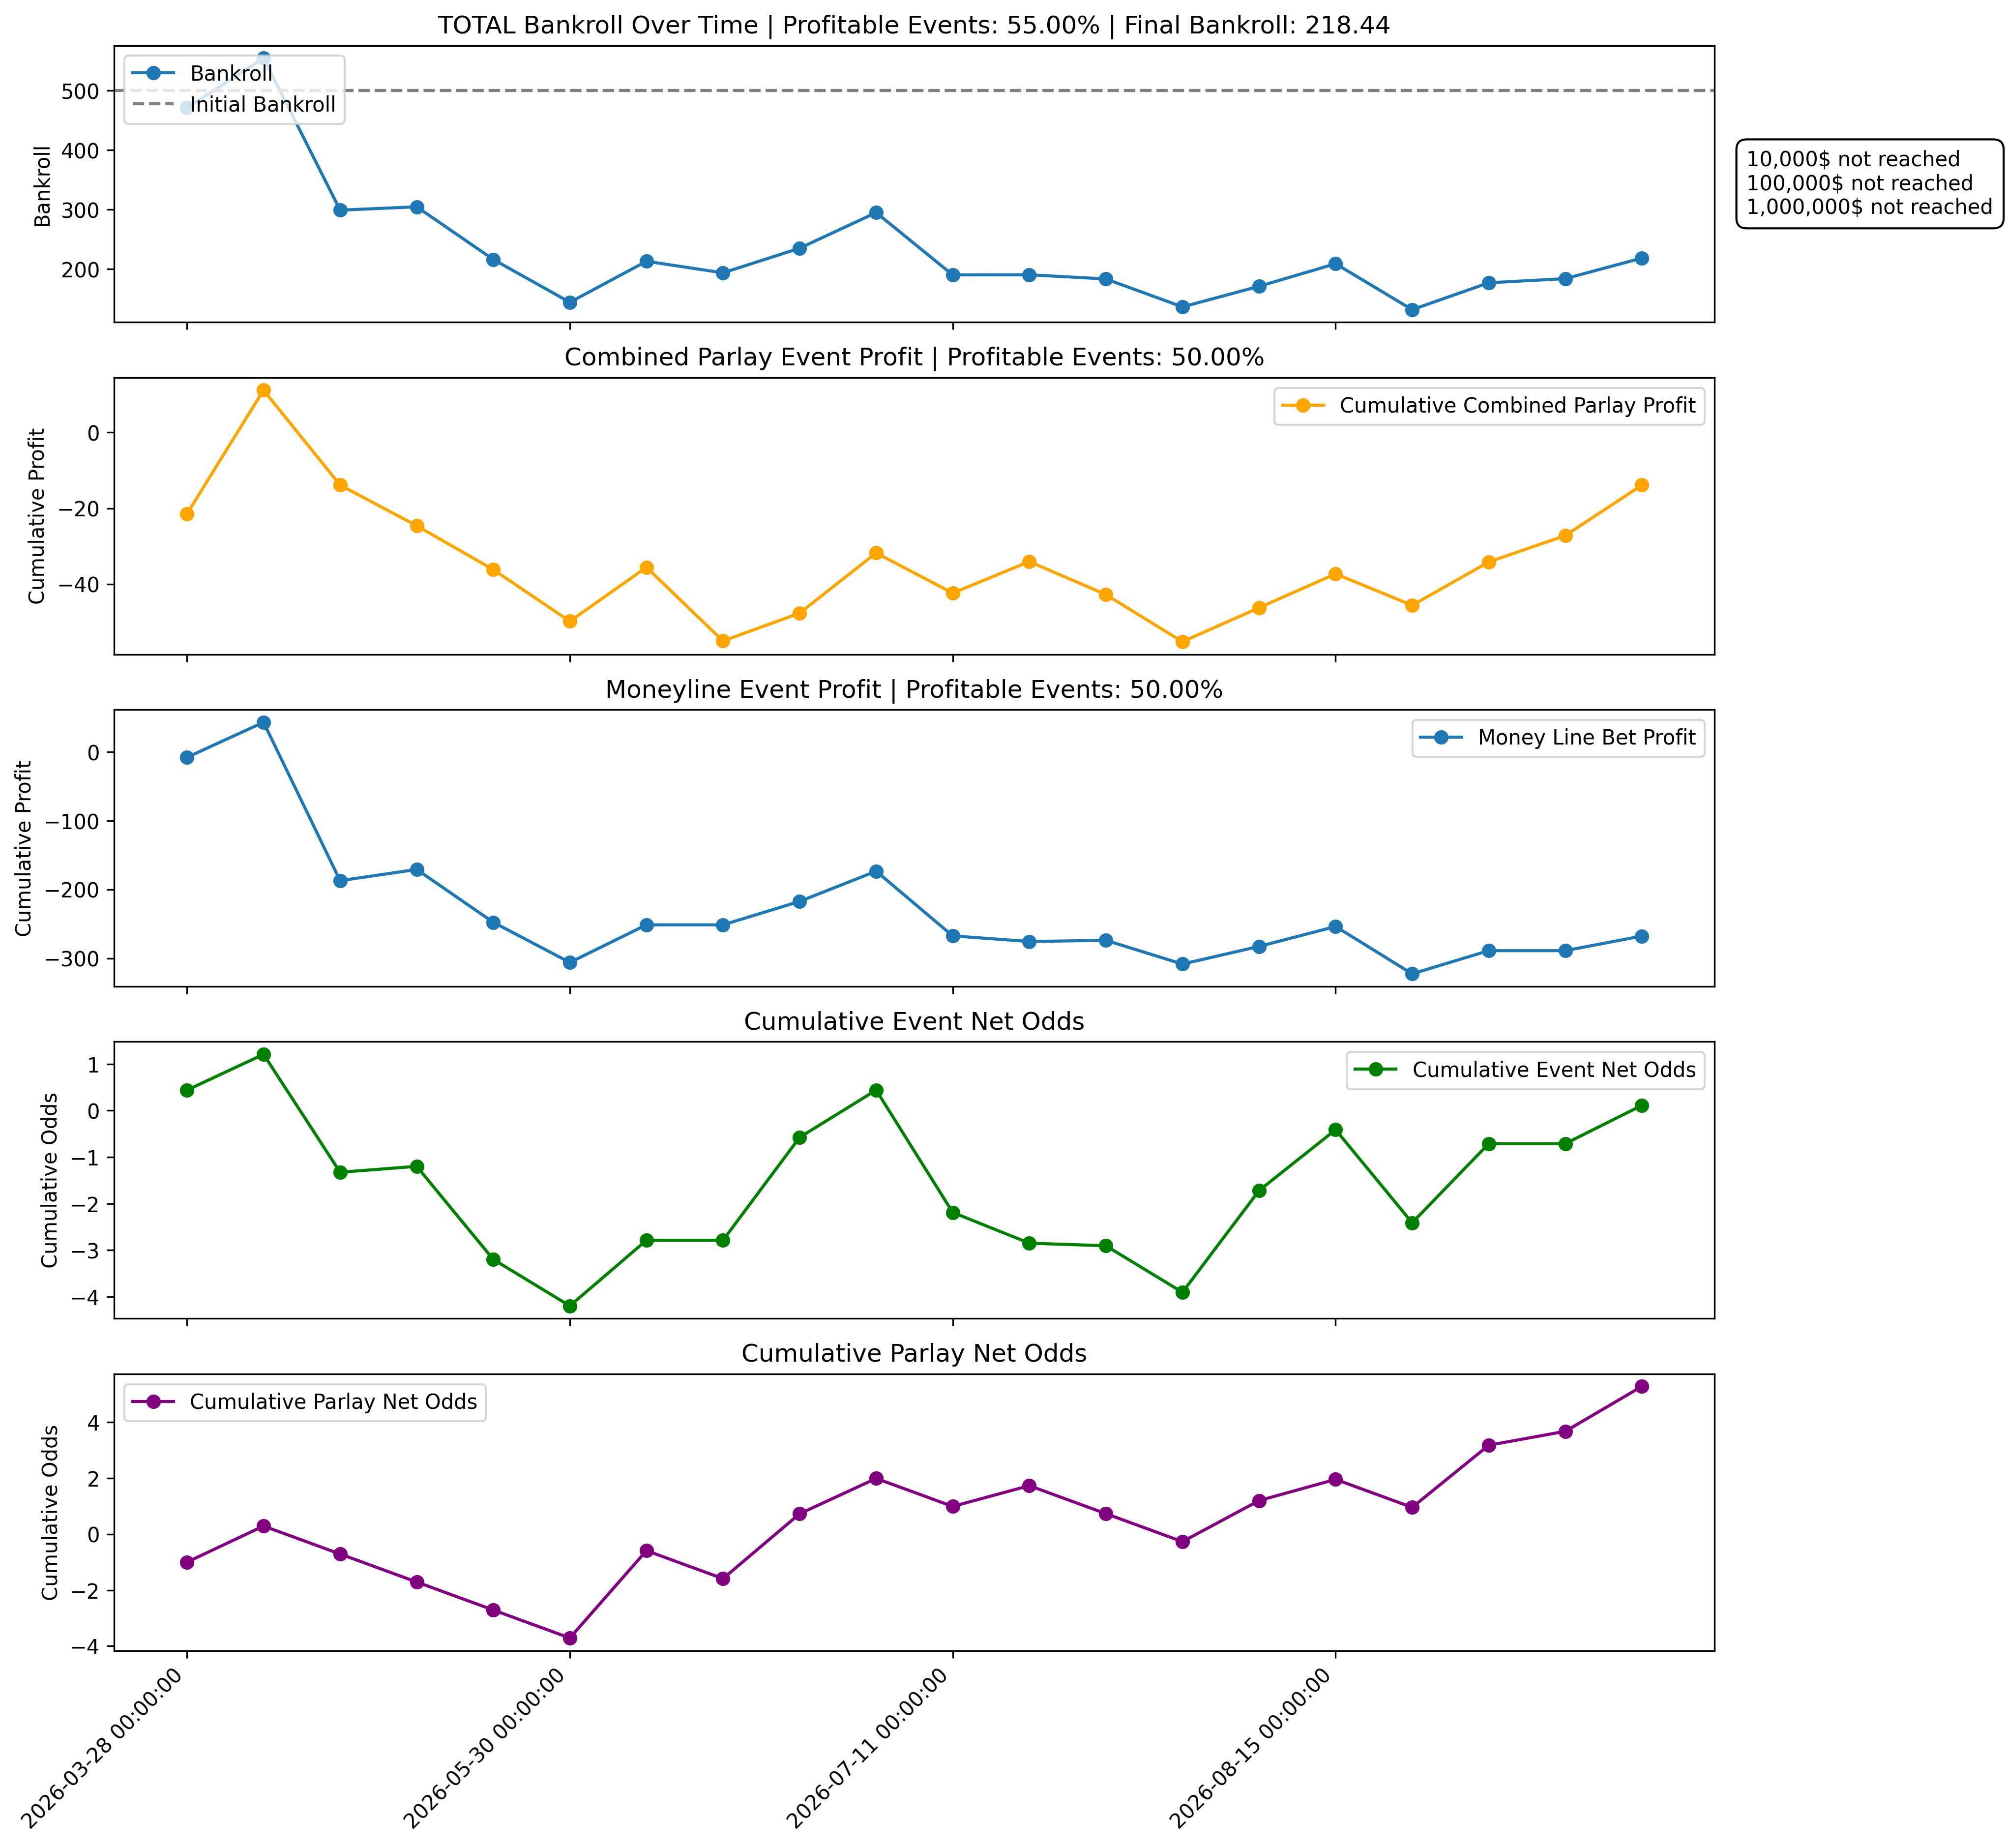

recorded_5_days_close2


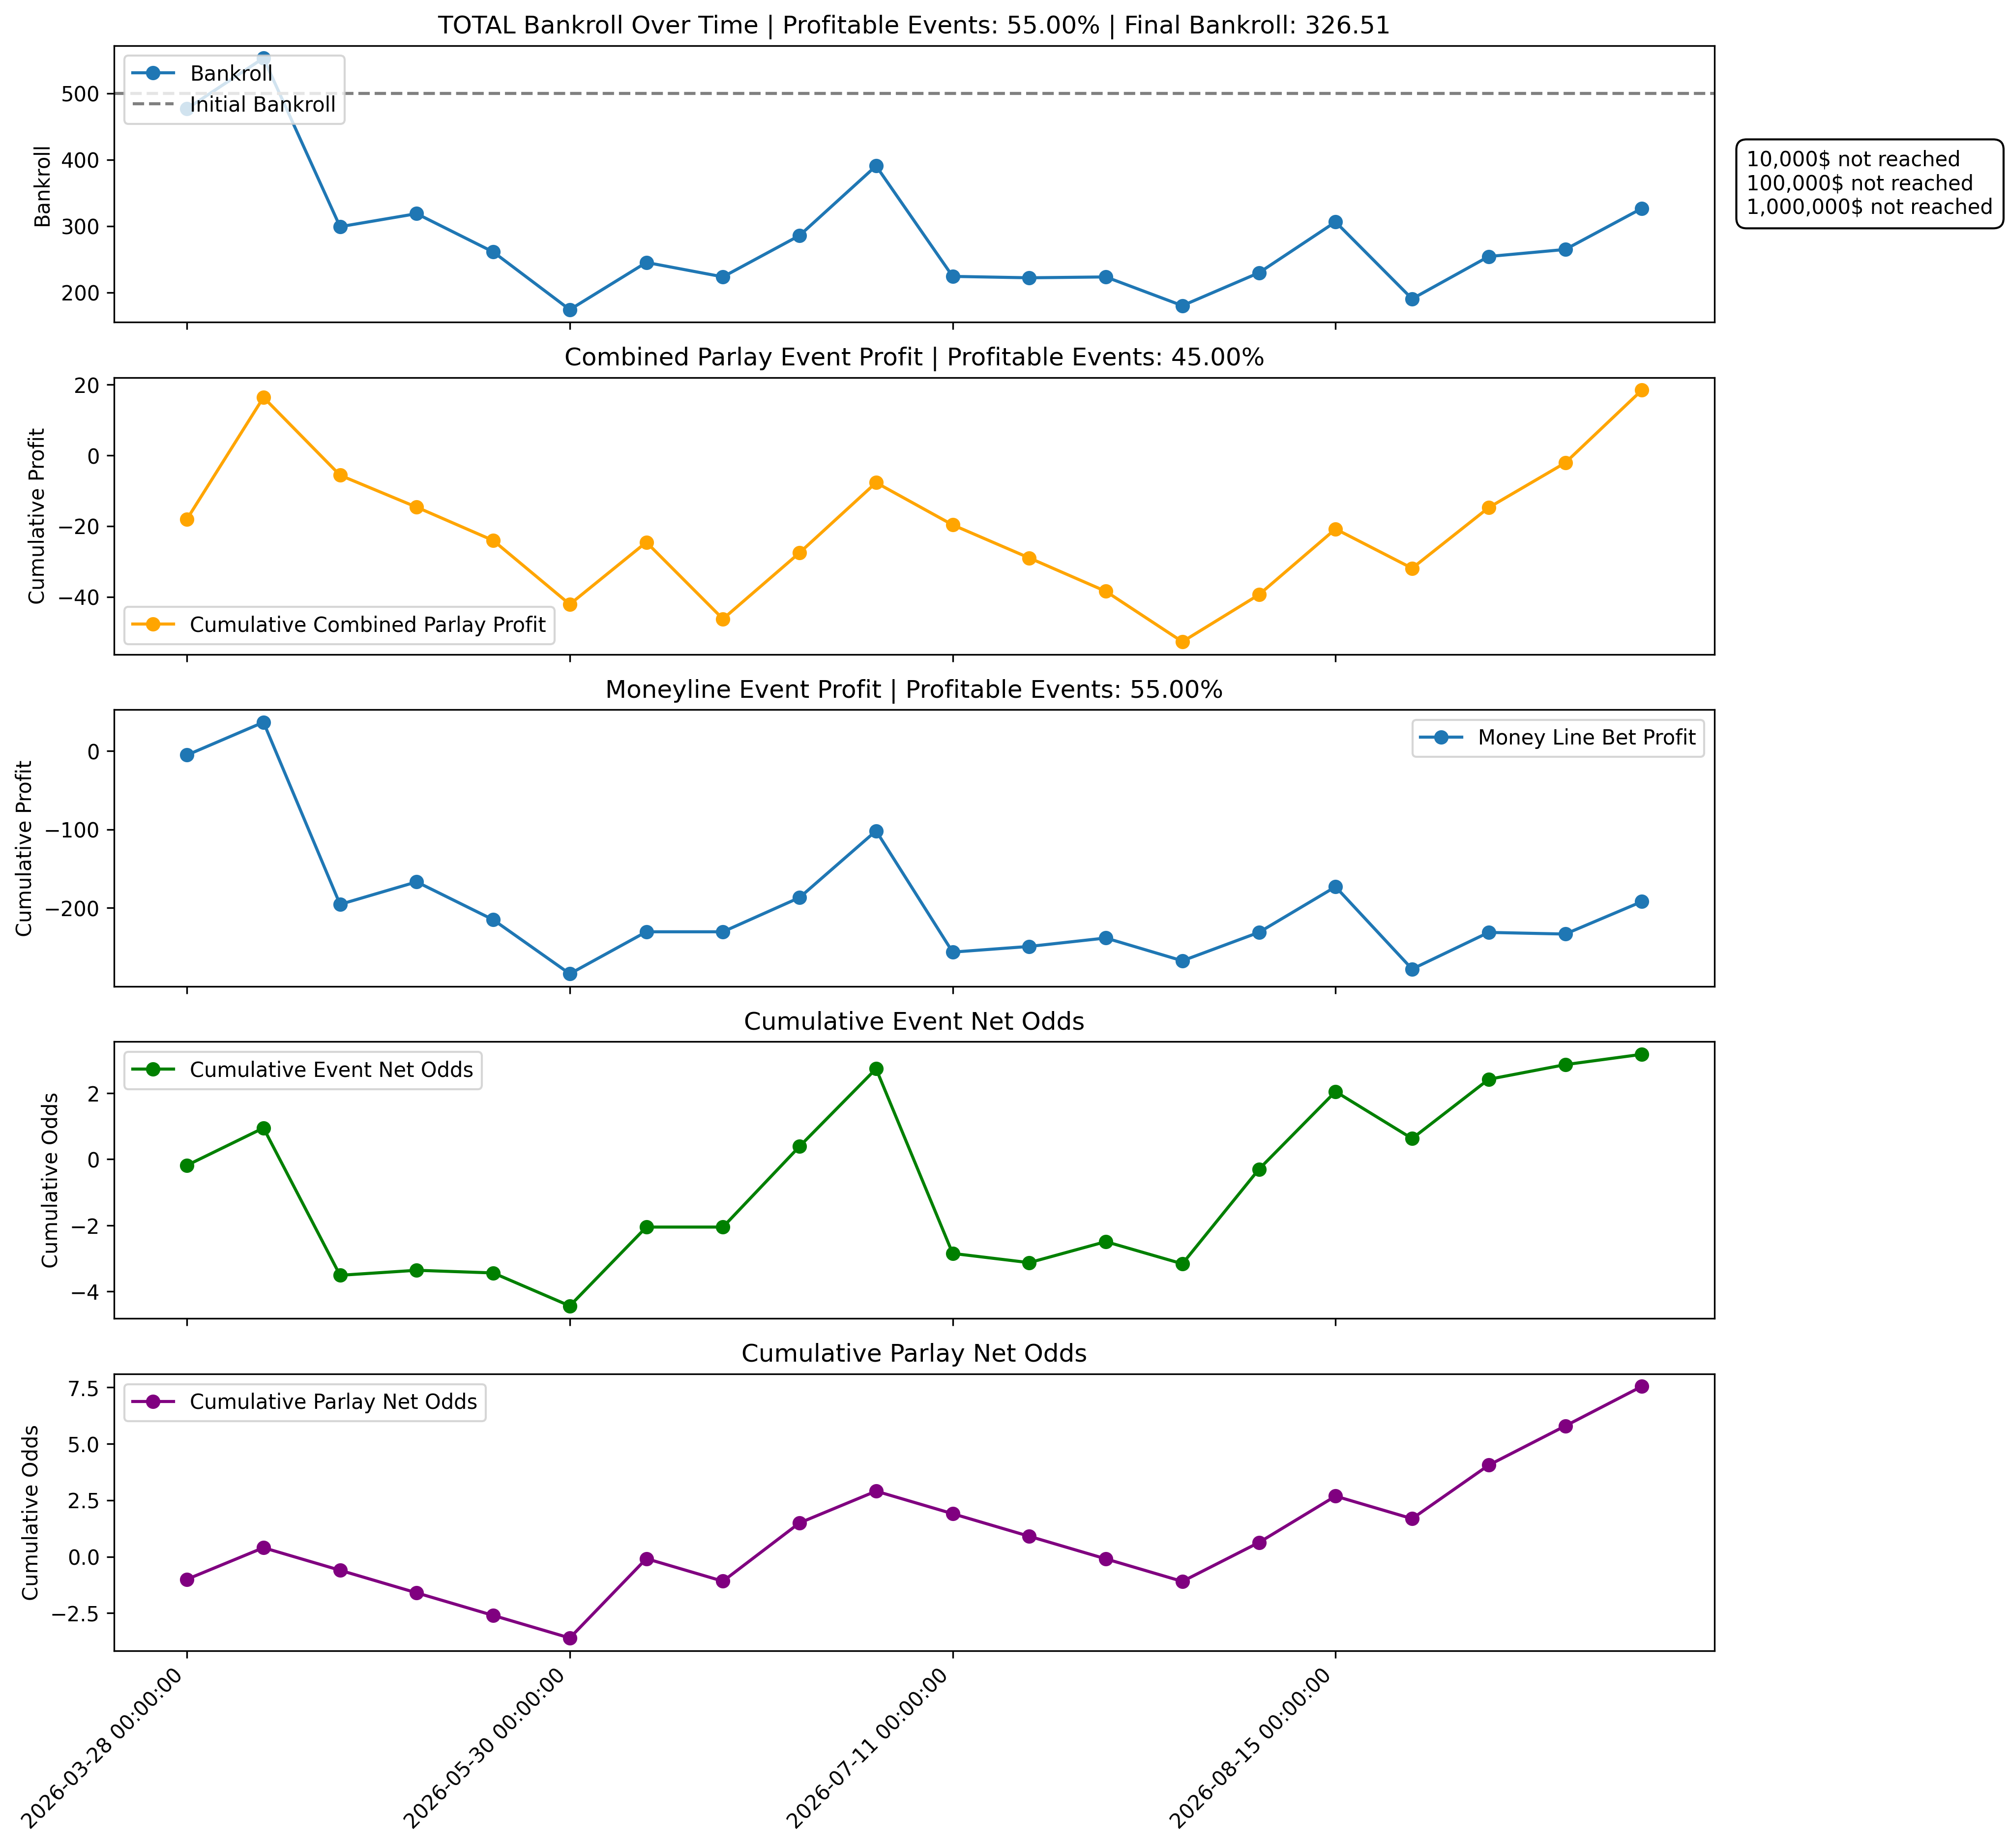

recorded_3_days_close1


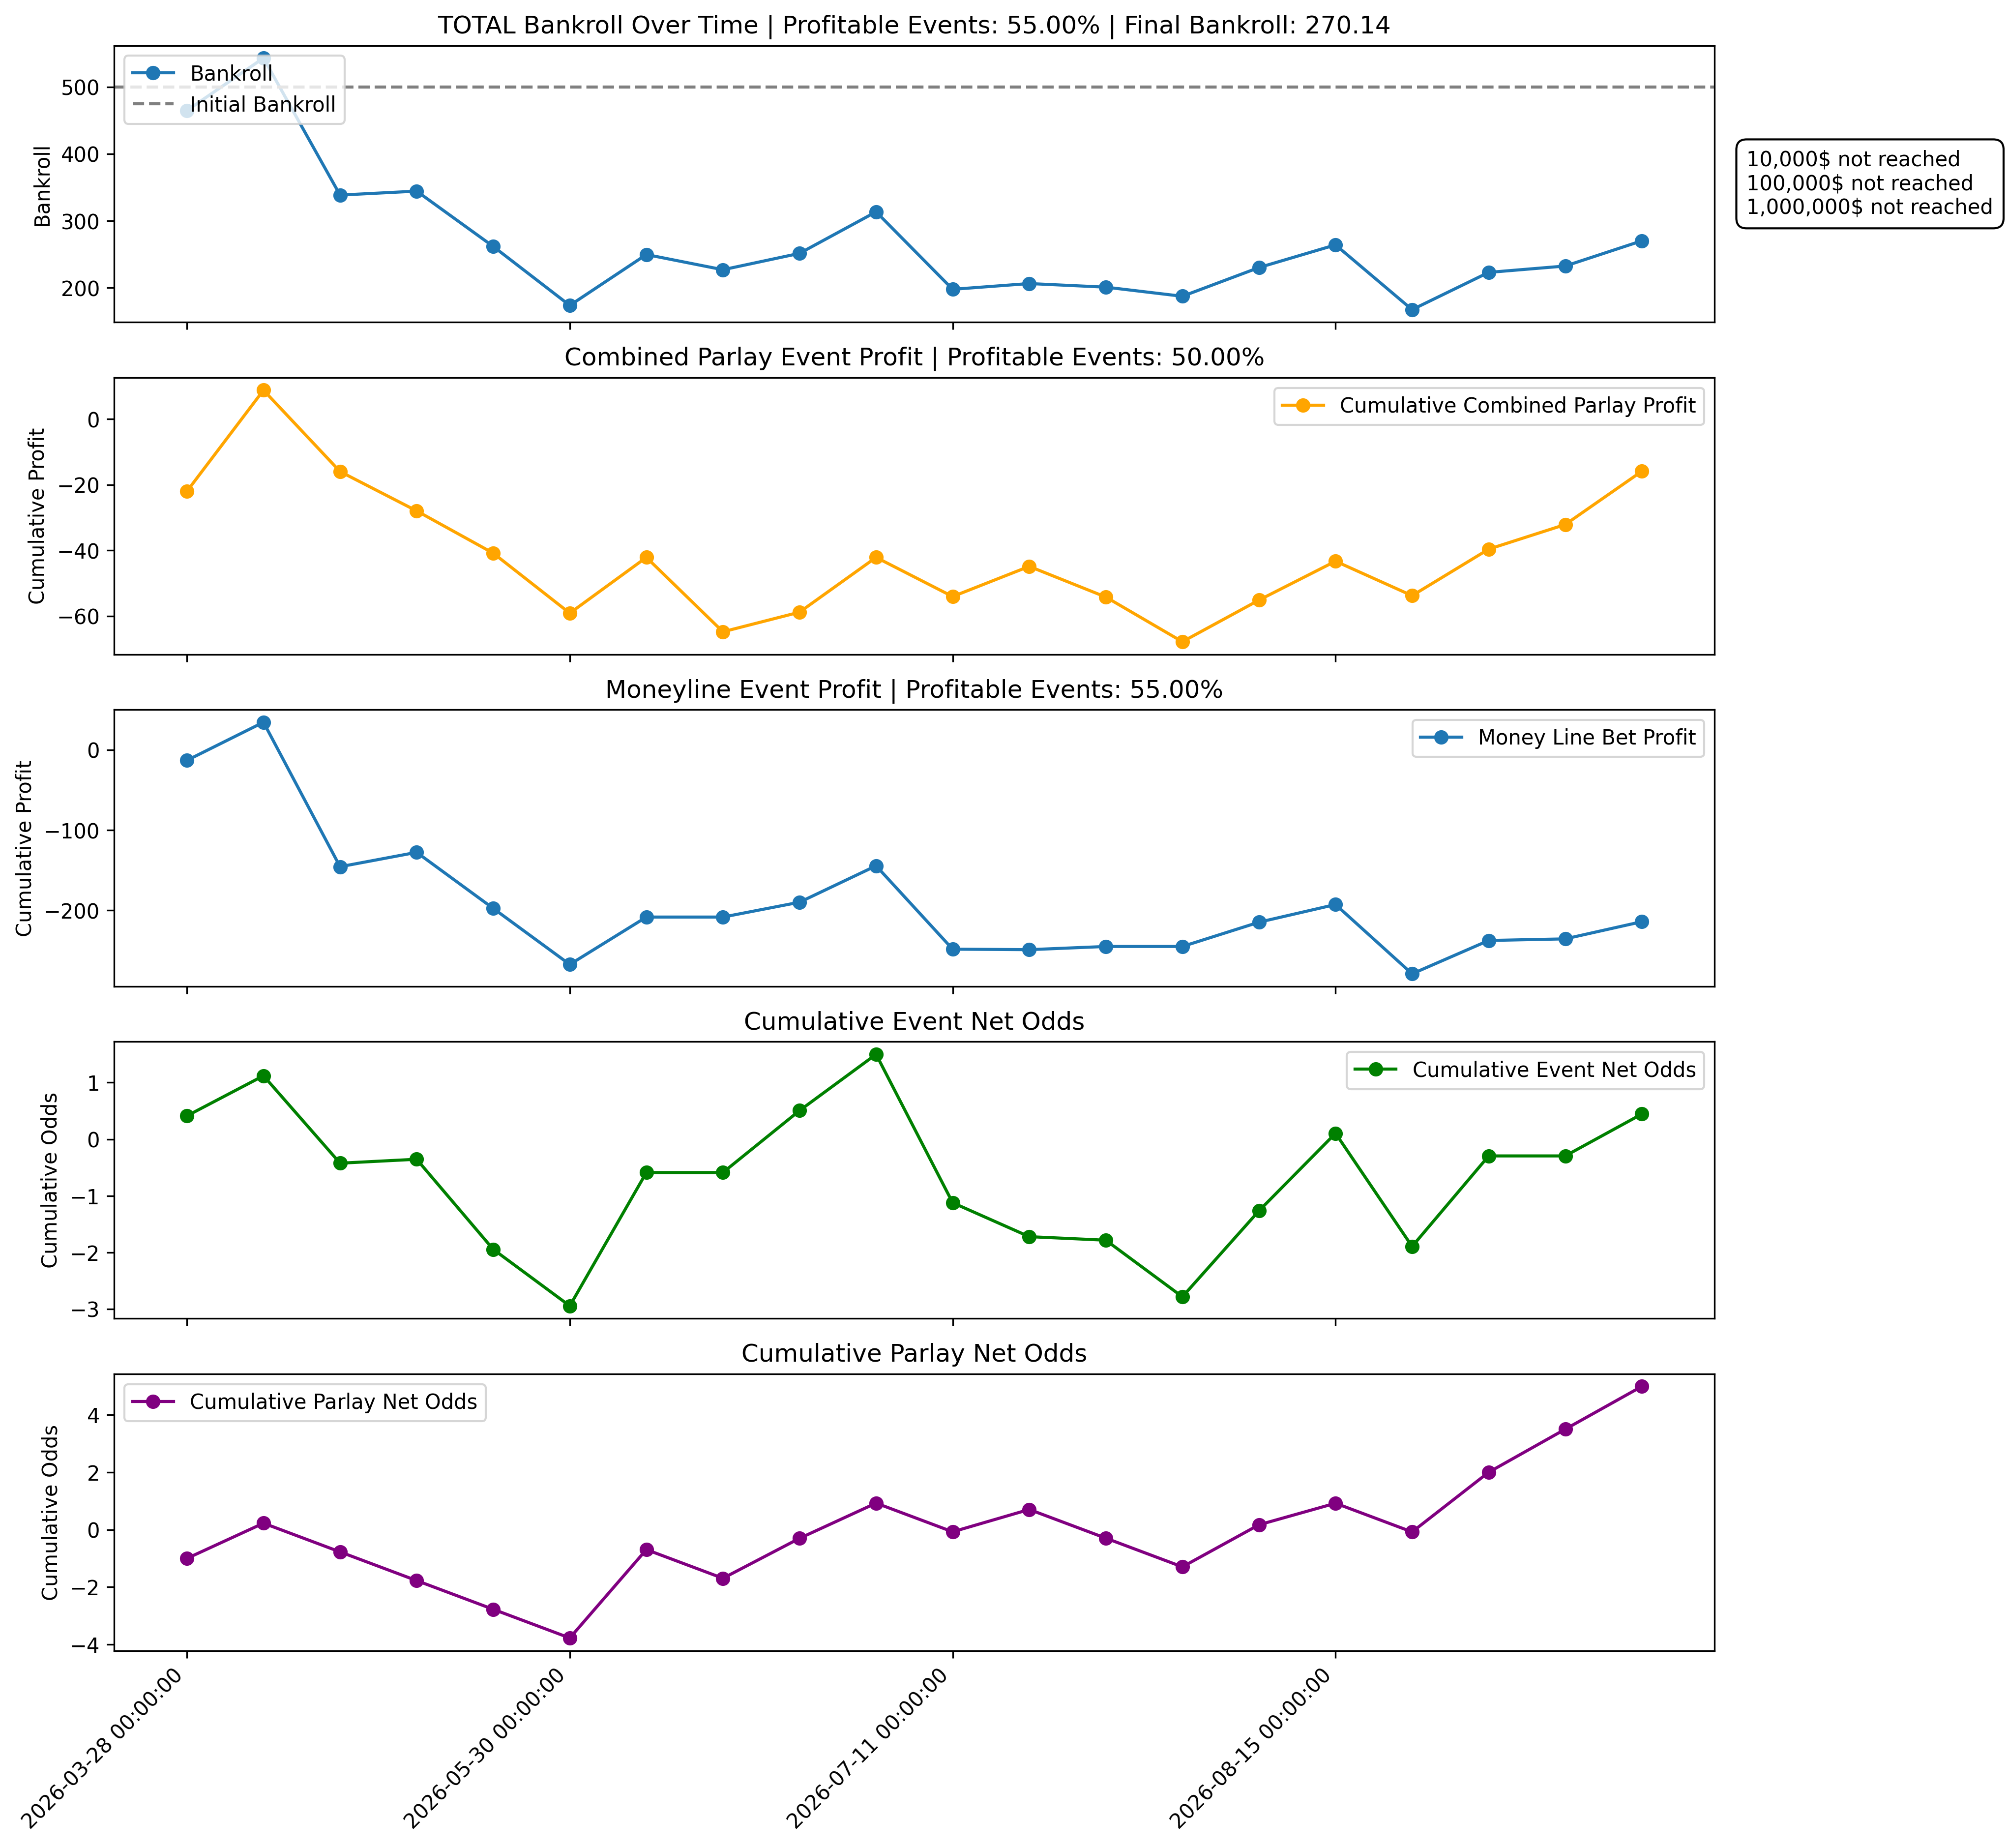

recorded_3_days_close2


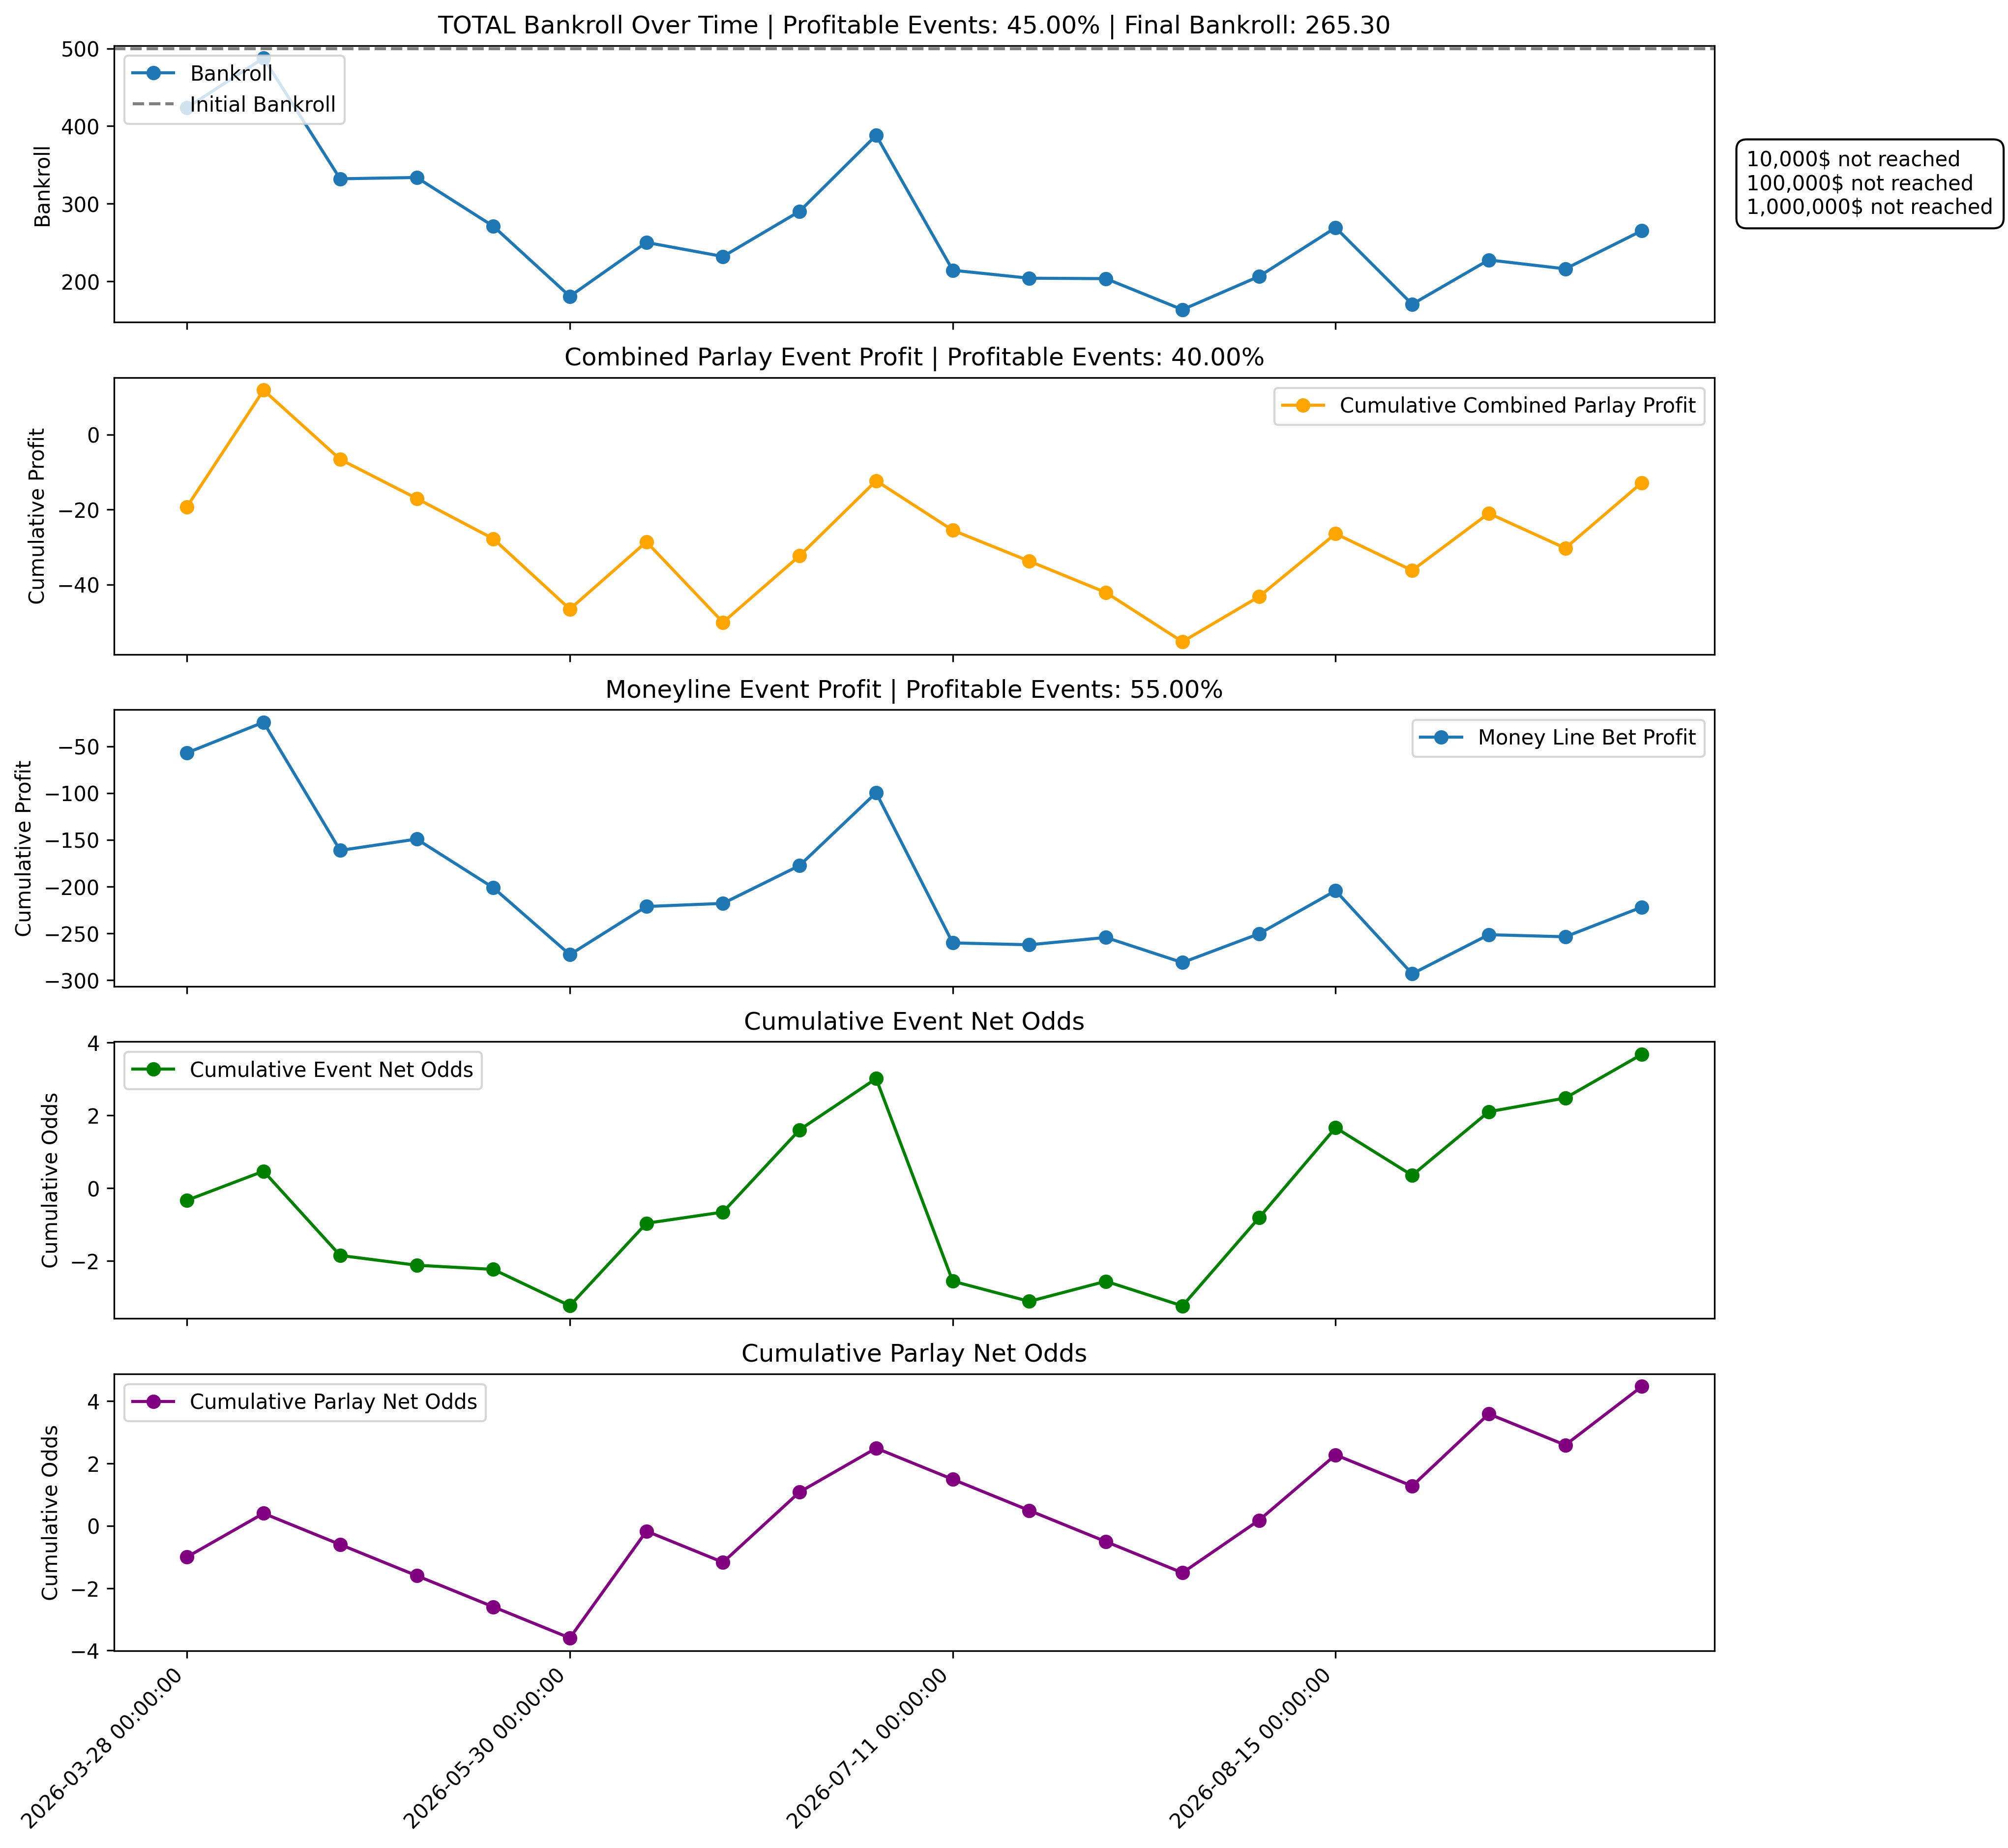

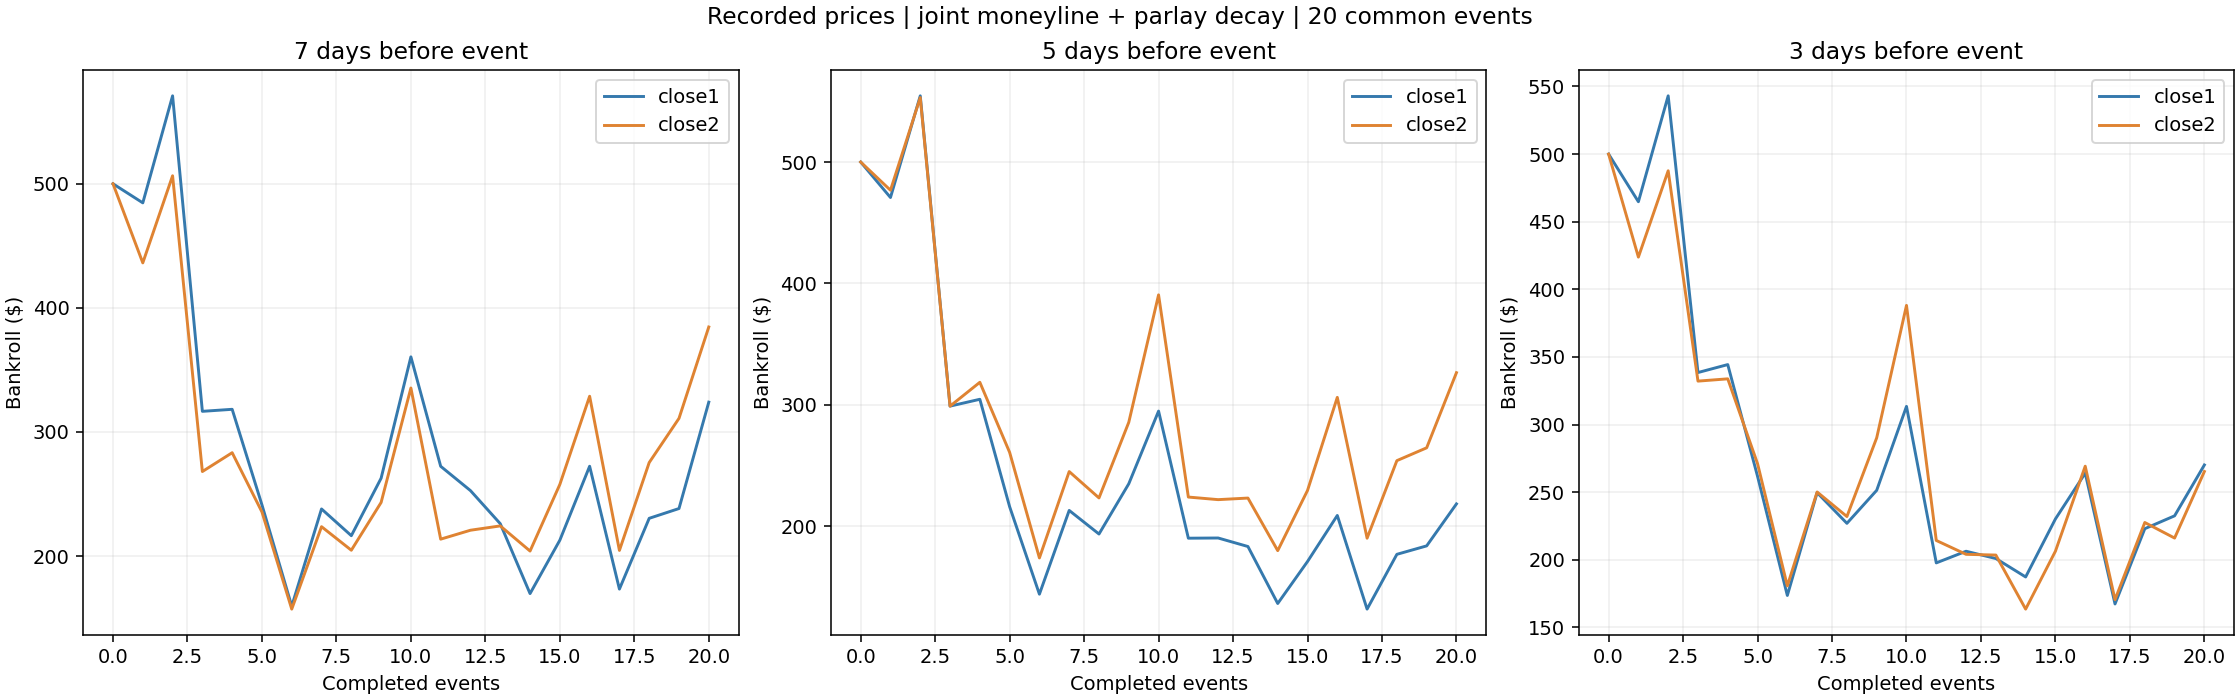

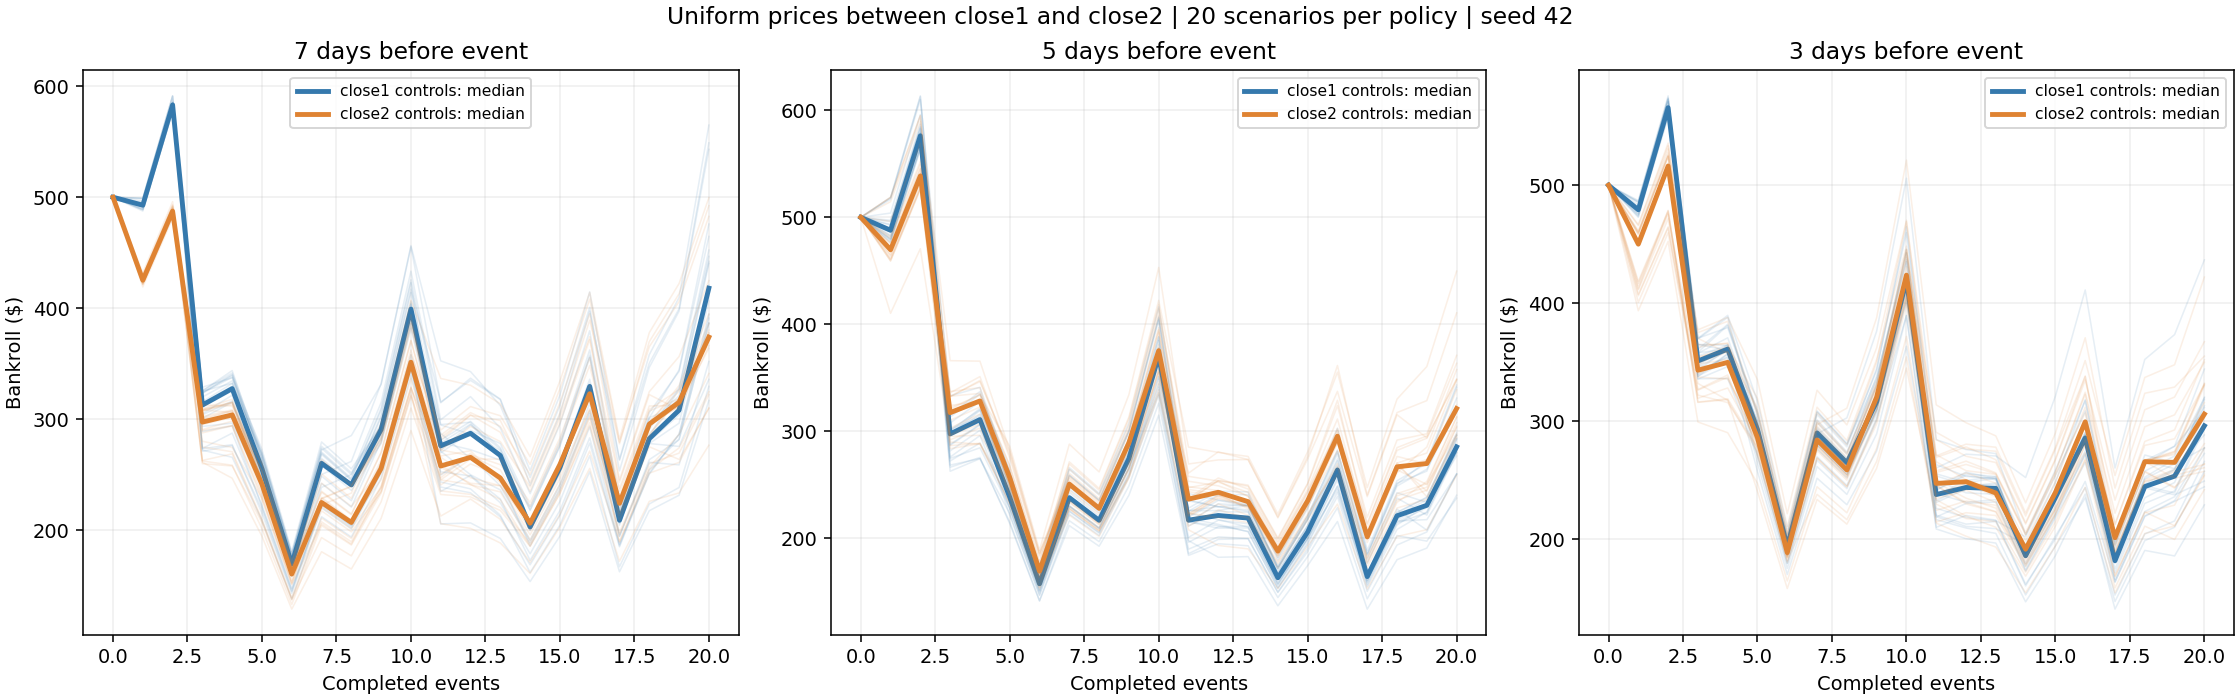

No eligible common event cohort: exact-day archive snapshots are missing or fights lack usable inputs.
validation: no_coverage | 0 events


,event_date,missing_days
0,2024-05-11,"3,5,7"
1,2024-05-18,"3,5,7"
2,2024-06-01,"3,5,7"
3,2024-06-08,"3,5,7"
4,2024-06-15,"3,5,7"
...,...,...
68,2025-12-13,"3,5,7"
69,2026-01-24,"3,5,7"
70,2026-01-31,"3,5,7"
71,2026-02-07,"3,5,7"


No eligible common event cohort: exact-day archive snapshots are missing or fights lack usable inputs.


In [9]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.Models.RiskManagement import lead_time_backtest
from ufc_betting.BettingStrategy.Backtest import backtest_functions
importlib.reload(backtest_functions)
importlib.reload(lead_time_backtest)

lead_time_lambdas = {
    "k_down": 49.91702161206258,
    "k_up": 0.5504910146566548,
    "k_parlay_down": 0.5760956787848726,
    "k_parlay_up": 0.18014878632477732,
}
lead_time_params = lead_time_backtest.load_lead_time_params(ROOT / "Data")
# One integer (e.g. 7) or multiple lead times. Cohort is shared across requested days.
days_out = (7, 5, 3)
lead_time_split_results = {}
for split in ("test", "validation"):
    result = lead_time_backtest.run_split_lead_time_backtests(
        ROOT / "Data",
        decay_rates=lead_time_lambdas,
        split=split,
        days_out=days_out,
        params=lead_time_params,
        n_paths=20,
        seed=42,
        initial_bankroll=500,
    )
    lead_time_split_results[split] = result
    print(f"{split}: {result['status']} | {len(result['dates'])} events")
    display(result["missing_days"])
    if result["status"] != "complete":
        print(result["message"])
        continue
    import pandas as pd
    display(pd.DataFrame({"date": result["dates"]}))
    display(result["summary"].groupby(["scenario", "days_out", "policy"])["ending_bankroll"].agg(["count", "median", "min", "max"]))
    for label, image_path in result["backtest_plots"].items():
        print(label)
        display(Image(filename=str(image_path)))
    display(Image(filename=str(result["recorded_plot"])))
    display(Image(filename=str(result["sampled_plot"])))


## Matched test-set, lead-time, and midpoint-price returns

All rows use the same matched fights/events. Test benchmarks include opening, close1, and close2 odds; full-test results are omitted. Opening uses its saved opening predictions, prices, and opening betting controls.

Total return is compounded bankroll change; average event return is the arithmetic mean across events. Midpoint prices are `(close1 decimal odds + close2 decimal odds) / 2` for each fighter, with predictions and allocations recalculated before `simulate_kelly`. Two midpoint rows identify the closing controls used.


In [ ]:
from pathlib import Path
import sys
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.Models.RiskManagement import lead_time_comparison
import importlib
importlib.reload(lead_time_comparison)
compare_lead_time_returns = lead_time_comparison.compare_lead_time_returns

comparison_run_dir = ROOT / "Data" / "model_results" / "lead_time_backtests" / "test"
lead_time_return_comparison = compare_lead_time_returns(ROOT / "Data", run_dir=comparison_run_dir)
display(lead_time_return_comparison.round(2))


Data,Odds,Total return (%),Average event return (%)
Test set (matched),open,-14.30,3.85
Test set (matched),close1,-72.03,-3.65
Test set (matched),close2,-51.78,-0.32
7 days out,close1,-35.19,1.67
7 days out,close2,-23.08,2.46
5 days out,close1,-56.31,-0.31
5 days out,close2,-34.70,1.95
3 days out,close1,-45.97,-0.05
3 days out,close2,-46.94,0.40
7 days out (midpoint prices),Midpoint / close1 controls,-19.90,3.20


## Validation-only opening odds and movement probability densities

Two continuous variables: opening decimal odds **X**, and movement magnitude **M = abs(closing - opening)**. For example, 2.00 to 1.70 has decrease magnitude 0.30. Both fighter sides from the saved validation CSVs are included; no test rows or intermediate archive snapshots are used. Close1 and close2 have separate rows, and decreases and increases have separate columns.

The first figure shows the **joint PDF f(X, M | direction)**. The second shows the **conditional PDF f(M | X, direction)**, answering how change is distributed at a given opening price, once its direction is specified. Each direction's joint PDF integrates to one over its full support. Color represents density, not the probability of an exact change. Probability is density integrated across an interval. Unchanged prices form a separate discrete mass; their counts are displayed below.

Fits a Gaussian KDE with Scott bandwidth after boundary-preserving transforms: log(X-1), and log(M) for increases or logit(M/(X-1)) for decreases. Densities include the Jacobian correction back to decimal units. Decreases cannot exceed X-1, since closing decimal odds must remain above 1. All valid observations are fitted; chart axes default to the 99th percentiles to keep the main distribution visible. Set `plot_quantile=1` to show full observed ranges.

The probability helper returns the chance of the direction given opening, the chance of the interval given opening AND direction, and their product: the chance of that direction AND interval given opening. The direction probabilities use the fitted opening marginals weighted by observed direction frequencies, including unchanged prices. These are descriptive estimates from validation, with sparse-tail uncertainty; both fighter sides within a fight are dependent. Quoted market prices are discrete in practice; KDE is a continuous approximation.


## Test-set price-change boxplots: seven days before event through closing

For each day (7 to 0), close1 and close2 boxplots appear side by side. Y = decimal price minus the fighter’s fixed test-set opening price. Decreases and increases have separate panels. Boxes show the 25th–75th percentiles and median; whiskers extend to the most extreme observations within 1.5 IQR of the quartiles. Dots show observations beyond the whiskers. Counts appear underneath.

Days 7–1 use the latest archived snapshot on each exact UTC date, restricted to test-set fights. Day 0 uses saved test closing prices. Missing observations are not filled; unchanged prices are excluded. Repeated fighter observations and opposing sides are dependent.


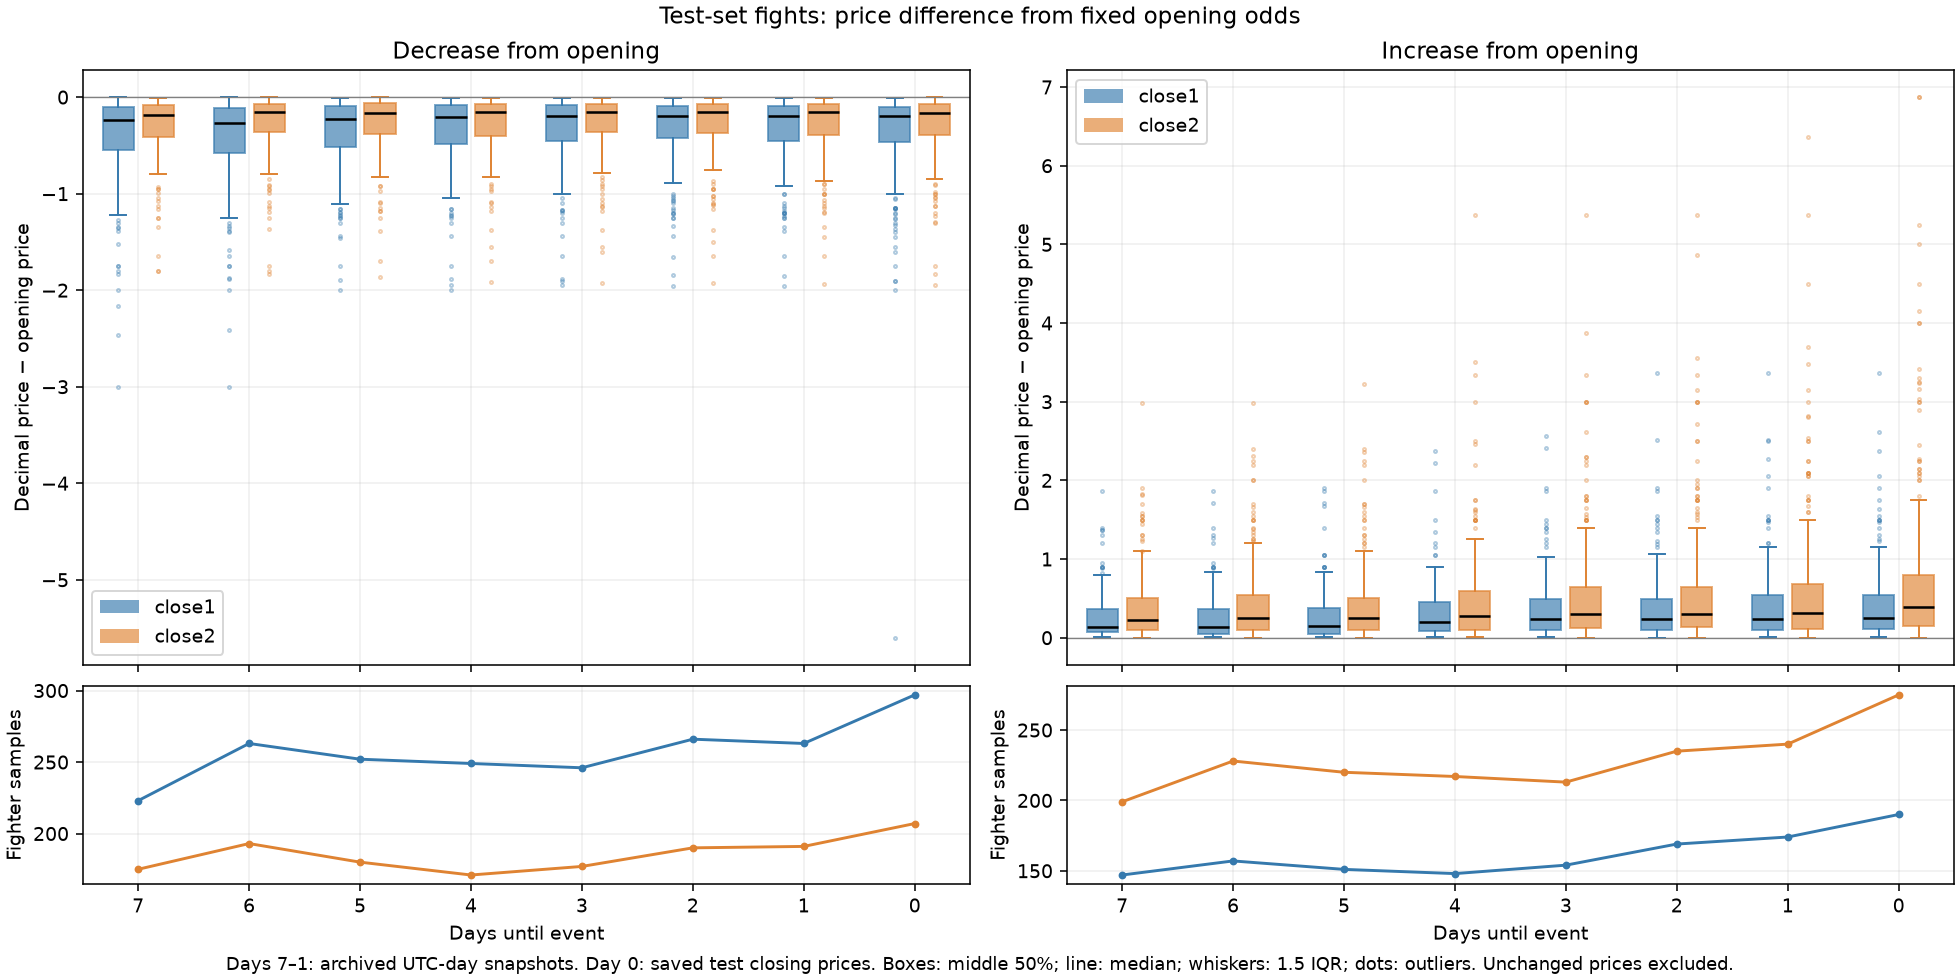

In [ ]:
from pathlib import Path
import sys
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ufc_betting").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import importlib
from ufc_betting.Models.LineMovement import test_price_paths
importlib.reload(test_price_paths)
plot_test_price_changes = test_price_paths.plot_test_price_changes

test_price_changes = plot_test_price_changes(ROOT / "Data")
display(Image(filename=str(test_price_changes["plot_path"])))
